# DHIL - heat-stress prevention for Hajj/Umrah (CAI 461, Project 2)
Run the cells from top to bottom. Do not run cells twice out of order.

Sections: 1 setup, 2 agent files, 3 model, 4 checks, 5 map, 6 scenarios.

## 1. Setup

In [ ]:
!pip -q install langsmith

In [ ]:
# LangSmith tracing (required by the course). Put your key in a Colab secret named LANGSMITH_API_KEY
# (key icon on the left, switch "Notebook access" on). Without a key everything still runs, with tracing off.
import os
try:
    from google.colab import userdata
    os.environ["LANGSMITH_API_KEY"] = userdata.get("LANGSMITH_API_KEY")
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "dhil-heat-stress"
except Exception:
    pass
print("LangSmith key found:", bool(os.environ.get("LANGSMITH_API_KEY")))

LangSmith key found: True


In [ ]:

import os
from google.colab import userdata

key = userdata.get("LANGSMITH_API_KEY").strip()

assert key.startswith("lsv2_pt_"), "Invalid API key prefix"

os.environ["LANGSMITH_API_KEY"] = key
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "dhil-heat-stress"
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"

os.environ.pop("LANGSMITH_WORKSPACE_ID", None)

print("LangSmith configured:", True)


LangSmith configured: True


In [ ]:
import os
os.makedirs("data", exist_ok=True)
for path in ("data/makkah_walk.graphml", "data/haram_features.csv", "health_model.joblib"):
    print(("OK      " if os.path.exists(path) else "MISSING ") + path)
print()
print("If data/makkah_walk.graphml or data/haram_features.csv is MISSING, run the upload cell below.")
print("If health_model.joblib is MISSING, the training cell in section 3 builds it.")

OK      data/makkah_walk.graphml
OK      data/haram_features.csv
OK      health_model.joblib

If data/makkah_walk.graphml or data/haram_features.csv is MISSING, run the upload cell below.
If health_model.joblib is MISSING, the training cell in section 3 builds it.


In [ ]:
# Upload cell: run only if a data file above is MISSING (choose the files from your computer)
from google.colab import files
for name, up in files.upload().items():
    os.replace(name, "data/" + name if name.endswith((".graphml", ".csv")) and name != "health_model.joblib" else name)
    print("saved", name)

Saving haram_features (1).csv to haram_features (1).csv
Saving health_model (1).joblib to health_model (1).joblib
Saving makkah_walk.graphml to makkah_walk.graphml
saved haram_features (1).csv
saved health_model (1).joblib
saved makkah_walk.graphml


## 2. Agent files (each cell writes one file)

In [ ]:
%%writefile messages.py
"""messages.py -- ACL-like messaging + base agent for DHIL."""
import itertools
from dataclasses import dataclass, field

PERFORMATIVES = {"INFORM", "REQUEST", "CFP", "PROPOSE", "ACCEPT", "REFUSE", "FAILURE"}
ONTOLOGY = "dhil-heat-stress"
_ids = itertools.count(1)


@dataclass
class Message:
    sender: str
    receiver: str
    performative: str
    content: dict
    ontology: str = ONTOLOGY
    conversation_id: str = ""
    in_reply_to: int = 0
    step: int = 0
    delivered: bool = True
    msg_id: int = field(default_factory=lambda: next(_ids))

    def __post_init__(self):
        if self.performative not in PERFORMATIVES:
            raise ValueError(f"Unknown performative: {self.performative}")

    def __str__(self):
        flag = "" if self.delivered else "  [UNDELIVERED]"
        return (f"#{self.msg_id} step={self.step} ({self.performative} :sender {self.sender} "
                f":receiver {self.receiver} :ontology {self.ontology} "
                f":conv {self.conversation_id or '-'} :content {self.content}){flag}")


class MessageBus:
    """Delivers messages between agents and keeps the log shown in the UI."""

    def __init__(self):
        self.agents = {}
        self.log = []
        self.failed = set()      # agents currently "down" (failure scenarios)
        self.step = 0

    def register(self, agent):
        self.agents[agent.name] = agent

    def fail(self, name):
        self.failed.add(name)

    def recover(self, name):
        self.failed.discard(name)

    def send(self, msg):
        msg.step = self.step
        target = self.agents.get(msg.receiver)
        if target is None or msg.receiver in self.failed:
            msg.delivered = False
        else:
            target.inbox.append(msg)
        self.log.append(msg)
        return msg


class BaseAgent:
    def __init__(self, name, bus):
        self.name = name
        self.bus = bus
        self.inbox = []
        self.status = "idle"
        bus.register(self)

    @property
    def is_failed(self):
        return self.name in self.bus.failed

    def send(self, receiver, performative, content, conversation_id="", in_reply_to=0):
        return self.bus.send(Message(self.name, receiver, performative, content,
                                     conversation_id=conversation_id, in_reply_to=in_reply_to))

    def read_inbox(self):
        msgs, self.inbox = self.inbox, []
        return msgs

Overwriting messages.py


In [ ]:
%%writefile tracing.py
"""tracing.py -- LangSmith tracing (observability) for the DHIL agents.

Spans are created with langsmith.trace. If the langsmith package or an API key is missing, or tracing is off,
every span does nothing, so the system works exactly the same without LangSmith.

Environment variables (the documented LangSmith ones): LANGSMITH_TRACING=true, LANGSMITH_API_KEY, LANGSMITH_PROJECT.
Call setup() before the first traced step, or set the variables before starting the program.
"""
import contextlib
import os

try:
    import langsmith as ls
except Exception:
    ls = None


def enabled():
    return (ls is not None and os.environ.get("LANGSMITH_TRACING", "").lower() == "true"
            and bool(os.environ.get("LANGSMITH_API_KEY")))


def setup(api_key=None, project=None):
    """Turn tracing on when a key is available. Returns a status line."""
    if api_key:
        os.environ["LANGSMITH_API_KEY"] = api_key.strip()
    if project:
        os.environ["LANGSMITH_PROJECT"] = project.strip()
    if ls is not None and os.environ.get("LANGSMITH_API_KEY"):
        os.environ["LANGSMITH_TRACING"] = "true"
    return status()


def turn_off():
    os.environ["LANGSMITH_TRACING"] = "false"
    return status()


def status():
    if ls is None:
        return "OFF (the langsmith package is not installed)"
    if not os.environ.get("LANGSMITH_API_KEY"):
        return "OFF (no LANGSMITH_API_KEY)"
    if os.environ.get("LANGSMITH_TRACING", "").lower() != "true":
        return "OFF (tracing is switched off)"
    return f"ON (project: {os.environ.get('LANGSMITH_PROJECT', 'default')})"


def plain(d):
    """Plain Python values only, so traces serialise cleanly."""
    out = {}
    for k, v in (d or {}).items():
        if hasattr(v, "item"):
            try:
                v = v.item()
            except Exception:
                v = str(v)
        out[str(k)] = v if isinstance(v, (int, float, str, bool, type(None))) else str(v)
    return out


class Span:
    def __init__(self):
        self.outputs = {}

    def set(self, **kw):
        self.outputs.update(plain(kw))


def _has_parent():
    try:
        return ls.get_current_run_tree() is not None
    except Exception:
        try:
            from langsmith.run_helpers import get_current_run_tree
            return get_current_run_tree() is not None
        except Exception:
            return True


@contextlib.contextmanager
def span(name, run_type="chain", inputs=None, root=False):
    """A traced step. Child spans are only recorded inside another trace (root=False), so loose calls
    such as unit tests do not create stray traces."""
    sp = Span()
    if not enabled() or (not root and not _has_parent()):
        yield sp
        return
    try:
        cm = ls.trace(name, run_type, inputs=plain(inputs))
    except Exception:
        yield sp
        return
    with cm as rt:
        yield sp
        try:
            rt.end(outputs=sp.outputs)
        except Exception:
            pass


def flush():
    """Send pending traces now (they are also sent in the background)."""
    if ls is None:
        return
    try:
        from langsmith.run_trees import get_cached_client
        get_cached_client().flush()
    except Exception:
        try:
            ls.Client().flush()
        except Exception:
            pass

Overwriting tracing.py


In [ ]:
%%writefile health_model.py
"""
health_model.py -- DHIL shared heat-stress model (single source of truth for
data generation AND the runtime Health Agent).

NOTE: the structure follows Hajj heat-illness literature and NWS heat-index bands;
the numeric weights are team ASSUMPTIONS, not fitted to real patient data.
Output is a simulated preventive-alert indicator, NOT a clinical diagnosis.
"""
import numpy as np

STEP_MIN = 5
SUN_ADD_F = 12.5              # sun adds ~10-15 F on top of the shade-based heat index
EXPOSURE_THRESHOLD_C = 32.2   # 90 F: NWS "Extreme Caution" starts
EXPOSURE_TAU_MIN = 60.0
EXPOSURE_NORM = 600.0
WATER_CAP_MIN = 240
REST_CAP_MIN = 240

# ASSUMPTION (team-defined): class cut-offs on the 0-100 risk score are our own design
# choice for the simulation. They are NOT official NWS categories.
CLASS_CUTS = (30.0, 50.0, 70.0)          # Low | Moderate | High | Critical
SATURATION_K = 1.6                       # smooth saturation (avoids hard clipping at 100)
CLASS_NAMES = ["Low", "Moderate", "High", "Critical"]
HIGH_THRESHOLD = CLASS_CUTS[1]


def heat_index_f(temp_c, rh):
    """NWS heat index (F) -- Rothfusz regression + NWS adjustments."""
    t = np.asarray(temp_c, dtype=float) * 9.0 / 5.0 + 32.0
    r = np.asarray(rh, dtype=float)

    simple = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + r * 0.094)
    avg = 0.5 * (simple + t)

    hi = (-42.379 + 2.04901523 * t + 10.14333127 * r - 0.22475541 * t * r
          - 0.00683783 * t * t - 0.05481717 * r * r + 0.00122874 * t * t * r
          + 0.00085282 * t * r * r - 0.00000199 * t * t * r * r)

    adj_dry = ((13.0 - r) / 4.0) * np.sqrt(np.clip((17.0 - np.abs(t - 95.0)) / 17.0, 0, None))
    hi = np.where((r < 13) & (t >= 80) & (t <= 112), hi - adj_dry, hi)
    adj_wet = ((r - 85.0) / 10.0) * ((87.0 - t) / 5.0)
    hi = np.where((r > 85) & (t >= 80) & (t <= 87), hi + adj_wet, hi)

    # regression is not valid beyond Steadman's range -> cap at 140 F
    return np.minimum(np.where(avg >= 80.0, hi, simple), 140.0)


def heat_index_c(temp_c, rh):
    return (heat_index_f(temp_c, rh) - 32.0) * 5.0 / 9.0


def effective_heat_f(hi_f, in_shade):
    return hi_f + np.where(np.asarray(in_shade) >= 1, 0.0, SUN_ADD_F)


def env_stress(hi_f_eff):
    """0 at 80 F (start of NWS 'Caution') .. 1 at 125 F ('Extreme Danger')."""
    return np.clip((hi_f_eff - 80.0) / 45.0, 0.0, 1.5)


def vulnerability(age, cardiac, diabetes, respiratory, acclimatized, bmi):
    age = np.asarray(age, dtype=float)
    bmi = np.asarray(bmi, dtype=float)
    return (1.0
            + 0.012 * np.clip(age - 40.0, 0, None)
            + 0.15 * np.asarray(cardiac)
            + 0.12 * np.asarray(diabetes)
            + 0.10 * np.asarray(respiratory)
            + 0.10 * (1 - np.asarray(acclimatized))
            + 0.08 * (bmi >= 30)
            + 0.05 * (bmi >= 35))


def step_state(fatigue, minutes_since_water, minutes_since_rest, exposure,
               age, bmi, hi_f, in_shade, walking):
    """Advance the dynamic pilgrim state by one step (5 minutes)."""
    walking = np.asarray(walking).astype(bool)
    shade = np.asarray(in_shade) >= 1
    hi_eff = effective_heat_f(hi_f, in_shade)
    e = env_stress(hi_eff)

    age_factor = 1.0 + np.clip(age - 40.0, 0, None) / 100.0
    obesity_factor = 1.0 + 0.10 * (np.asarray(bmi) >= 30)
    gain = 1.2 * (1.0 + e) * age_factor * obesity_factor
    recovery = np.where(shade, 4.0, 2.0)
    fatigue = np.clip(fatigue + np.where(walking, gain, -recovery), 0.0, 100.0)

    minutes_since_water = np.minimum(WATER_CAP_MIN, minutes_since_water + STEP_MIN)
    minutes_since_rest = np.where(
        walking, np.minimum(REST_CAP_MIN, minutes_since_rest + STEP_MIN),
        np.where(shade, 0.0, minutes_since_rest))

    hi_eff_c = (hi_eff - 32.0) * 5.0 / 9.0
    excess = np.clip(hi_eff_c - EXPOSURE_THRESHOLD_C, 0.0, None)
    exposure = exposure * np.exp(-STEP_MIN / EXPOSURE_TAU_MIN) + excess * STEP_MIN

    return fatigue, minutes_since_water, minutes_since_rest, exposure


def latent_risk(age, cardiac, diabetes, respiratory, acclimatized, bmi,
                fatigue, minutes_since_water, minutes_since_rest, exposure,
                hi_f, in_shade):
    """Reference risk score 0..100 (also the rule-based fallback of the Health Agent)."""
    e = env_stress(effective_heat_f(hi_f, in_shade))
    f = np.asarray(fatigue) / 100.0
    d = np.clip(np.asarray(minutes_since_water) / 180.0, 0, 1)
    x = np.clip(np.asarray(exposure) / EXPOSURE_NORM, 0, 1)
    r = np.clip(np.asarray(minutes_since_rest) / 120.0, 0, 1)
    inner = 0.30 + 0.30 * f + 0.25 * d + 0.25 * x + 0.10 * r
    v = vulnerability(age, cardiac, diabetes, respiratory, acclimatized, bmi)
    raw = e * inner * v
    # smooth saturation: in extreme heat the score keeps responding to
    # shade / water / rest instead of being stuck at 100
    return 100.0 * (1.0 - np.exp(-SATURATION_K * raw))

def risk_to_class(score):
    return np.digitize(score, CLASS_CUTS)

Overwriting health_model.py


In [ ]:
%%writefile generate_data.py
"""
generate_data.py  --  builds the synthetic training set for the DHIL Health Agent
===============================================================================
Method (simulation-based, not random columns):
  1. Sample virtual pilgrims (profile) and a weather day (Makkah-like range).
  2. Simulate each pilgrim walking for up to 3 hours with the SAME dynamics the
     runtime Health Agent uses (health_model.step_state).
  3. Take random snapshots of the state -> features.
  4. Label each snapshot:
       risk_class  : from the reference risk score (+ small Gaussian noise)
       ttr_min     : minutes until the score reaches 'High' if the pilgrim keeps
                     walking, same weather, same shade, no water  (rollout).
                     Censored at 120 min.

Run:  python generate_data.py            (writes data/health_dataset.csv)
"""
import argparse
import numpy as np
import pandas as pd
import health_model as hm

TRIP_STEPS = 36            # 36 x 5 min = 3 hours
TTR_HORIZON_STEPS = 24     # 24 x 5 min = 120 minutes
LABEL_NOISE_SD = 3.5       # label noise (score points)

FEATURES = [
    "age", "sex", "bmi", "has_cardiac", "has_diabetes", "has_respiratory",
    "acclimatized", "fatigue", "minutes_since_water", "minutes_since_rest",
    "cumulative_heat_exposure", "heat_index_c", "in_shade",
]


# --------------------------------------------------------------- sampling
def sample_profiles(rng, n):
    """Pilgrim profiles. Distributions are assumptions (documented in report):
    skewed to older ages; comorbidity prevalence grows with age."""
    age = np.clip(rng.normal(55, 14, n), 18, 85).round()
    sex = rng.integers(0, 2, n)                              # 0 = female, 1 = male
    bmi = np.clip(rng.normal(27.5, 5.0, n), 17, 45).round(1)
    over30 = np.clip(age - 30, 0, None)
    cardiac = (rng.random(n) < np.clip(0.05 + 0.006 * over30, 0, 0.45)).astype(int)
    diabetes = (rng.random(n) < np.clip(0.04 + 0.004 * over30, 0, 0.30)).astype(int)
    respiratory = (rng.random(n) < 0.07).astype(int)
    acclimatized = (rng.random(n) < 0.35).astype(int)        # most pilgrims arrive from abroad
    return age, sex, bmi, cardiac, diabetes, respiratory, acclimatized


def sample_weather_day(rng, n):
    """Per-pilgrim day: Makkah-like range (cool season .. hot season)."""
    tmax = rng.uniform(28, 46, n)
    tmin = tmax - rng.uniform(8, 14, n)
    # hotter days are drier in Makkah-like climates (assumption)
    rh_day = np.clip(rng.uniform(10, 60, n) - 0.8 * (tmax - 30), 8, 60)
    start_hour = rng.uniform(6, 17, n)
    return tmax, tmin, rh_day, start_hour


def weather_at(hour, tmax, tmin, rh_day):
    """Diurnal curve: peak ~13:00, RH lower when hotter."""
    shape = np.clip(np.sin(np.pi * (hour - 6.0) / 14.0), 0, 1)
    temp = tmin + (tmax - tmin) * shape
    rh = np.clip(rh_day * (1.5 - 0.5 * shape), 5, 95)
    return temp, rh


# -------------------------------------------------------------- simulation
def simulate(n_pilgrims, seed):
    rng = np.random.default_rng(seed)
    age, sex, bmi, card, diab, resp, acc = sample_profiles(rng, n_pilgrims)
    tmax, tmin, rh_day, hour0 = sample_weather_day(rng, n_pilgrims)

    fatigue = rng.uniform(0, 35, n_pilgrims)
    msw = rng.uniform(0, 90, n_pilgrims)
    msr = rng.uniform(0, 60, n_pilgrims)
    expo = rng.uniform(0, 250, n_pilgrims)
    shade = (rng.random(n_pilgrims) < 0.3).astype(int)

    traj = {k: [] for k in ["fatigue", "msw", "msr", "expo", "shade", "temp", "rh", "hi_f"]}
    for s in range(TRIP_STEPS):
        hour = hour0 + s * hm.STEP_MIN / 60.0
        temp, rh = weather_at(hour, tmax, tmin, rh_day)
        hi_f = hm.heat_index_f(temp, rh)

        # behaviour of the virtual pilgrim this step
        p_walk = np.clip(0.85 - 0.50 * fatigue / 100.0, 0.25, 0.90)
        walking = rng.random(n_pilgrims) < p_walk
        # shade as a 2-state Markov chain (~30% of the route is shaded)
        flip_to_shade = (shade == 0) & (rng.random(n_pilgrims) < 0.10)
        flip_to_sun = (shade == 1) & (rng.random(n_pilgrims) < 0.25)
        shade = np.where(flip_to_shade, 1, np.where(flip_to_sun, 0, shade))
        # drinking: more likely once thirsty
        p_drink = np.where(msw > 90, 0.15, 0.03)
        msw = np.where(rng.random(n_pilgrims) < p_drink, 0.0, msw)

        fatigue, msw, msr, expo = hm.step_state(
            fatigue, msw, msr, expo, age, bmi, hi_f, shade, walking)

        for k, v in zip(traj.keys(), [fatigue, msw, msr, expo, shade, temp, rh, hi_f]):
            traj[k].append(np.array(v, copy=True))

    traj = {k: np.stack(v) for k, v in traj.items()}      # shape (steps, pilgrims)
    return dict(age=age, sex=sex, bmi=bmi, card=card, diab=diab, resp=resp,
                acc=acc), traj, rng


def time_to_high(prof, snap, hi_f):
    """Rollout: keep walking, same weather/shade, no water. Returns minutes
    until risk >= HIGH threshold (0 if already there), censored at horizon."""
    n = len(hi_f)
    fat, msw, msr, expo = snap["fatigue"].copy(), snap["msw"].copy(), snap["msr"].copy(), snap["expo"].copy()
    shade = snap["shade"]
    ttr = np.full(n, np.nan)

    def risk_now():
        return hm.latent_risk(prof["age"], prof["card"], prof["diab"], prof["resp"],
                              prof["acc"], prof["bmi"], fat, msw, msr, expo, hi_f, shade)

    ttr[risk_now() >= hm.HIGH_THRESHOLD] = 0.0
    for step in range(1, TTR_HORIZON_STEPS + 1):
        fat, msw, msr, expo = hm.step_state(
            fat, msw, msr, expo, prof["age"], prof["bmi"], hi_f, shade, np.ones(n, bool))
        crossed = np.isnan(ttr) & (risk_now() >= hm.HIGH_THRESHOLD)
        ttr[crossed] = step * hm.STEP_MIN
    censored = np.isnan(ttr)
    ttr[censored] = TTR_HORIZON_STEPS * hm.STEP_MIN
    return ttr, censored.astype(int)


def build_dataset(n_pilgrims=10000, snaps_per_pilgrim=2, seed=42):
    prof, traj, rng = simulate(n_pilgrims, seed)
    rows = []
    for j in range(snaps_per_pilgrim):
        idx = rng.integers(0, TRIP_STEPS, n_pilgrims)
        pil = np.arange(n_pilgrims)
        snap = {k: traj[k][idx, pil] for k in ["fatigue", "msw", "msr", "expo", "shade", "temp", "rh", "hi_f"]}

        score = hm.latent_risk(prof["age"], prof["card"], prof["diab"], prof["resp"],
                               prof["acc"], prof["bmi"], snap["fatigue"], snap["msw"],
                               snap["msr"], snap["expo"], snap["hi_f"], snap["shade"])
        noisy = np.clip(score + rng.normal(0, LABEL_NOISE_SD, n_pilgrims), 0, 100)
        ttr, cens = time_to_high(prof, snap, snap["hi_f"])

        df = pd.DataFrame({
            "pilgrim_id": pil,
            "age": prof["age"], "sex": prof["sex"], "bmi": prof["bmi"],
            "has_cardiac": prof["card"], "has_diabetes": prof["diab"],
            "has_respiratory": prof["resp"], "acclimatized": prof["acc"],
            "fatigue": snap["fatigue"].round(2),
            "minutes_since_water": snap["msw"].round(1),
            "minutes_since_rest": snap["msr"].round(1),
            "cumulative_heat_exposure": snap["expo"].round(2),
            "heat_index_c": ((snap["hi_f"] - 32) * 5 / 9).round(2),
            "in_shade": snap["shade"],
            "air_temp_c": snap["temp"].round(1), "humidity_pct": snap["rh"].round(1),
            "risk_score": noisy.round(2),
            "risk_class": hm.risk_to_class(noisy),
            "ttr_min": ttr, "ttr_censored": cens,
        })
        rows.append(df)
    out = pd.concat(rows, ignore_index=True)
    out["risk_class_name"] = out["risk_class"].map(dict(enumerate(hm.CLASS_NAMES)))
    out["ttr_bucket"] = pd.cut(out["ttr_min"], [-1, 0, 15, 30, 60, 1e9],
                               labels=["now", "<=15", "15-30", "30-60", ">60"]).astype(str)
    return out


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--pilgrims", type=int, default=10000)
    ap.add_argument("--snaps", type=int, default=2)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--out", default="data/health_dataset.csv")
    a = ap.parse_args()
    df = build_dataset(a.pilgrims, a.snaps, a.seed)
    df.to_csv(a.out, index=False)
    print(f"saved {len(df)} rows -> {a.out}")
    print("\nrisk class distribution (%):")
    print((df["risk_class_name"].value_counts(normalize=True) * 100).round(1).reindex(hm.CLASS_NAMES))
    print("\ntime-to-High bucket distribution (%):")
    print((df["ttr_bucket"].value_counts(normalize=True) * 100).round(1))

Overwriting generate_data.py


In [ ]:
%%writefile health_agent.py
"""health_agent.py -- Health Agent: ML risk classifier + rule-based fallback."""
import numpy as np
import pandas as pd
import joblib
import health_model as hm
import tracing
from messages import BaseAgent

DEFAULT_MIDPOINTS = np.array([15.0, 40.0, 60.0, 85.0])
LOW_CONFIDENCE = 0.50          # below this -> escalate conservatively
TTR_HORIZON_STEPS = 24         # 24 x 5 min = 120 minutes


class HealthAgent(BaseAgent):
    def __init__(self, bus, profile, model_path="health_model.joblib",
                 prevention_name="prevention"):
        super().__init__("health", bus)
        self.profile = dict(profile)
        self.prevention = prevention_name
        self.fatigue = float(profile.get("fatigue", 10))
        self.msw = float(profile.get("minutes_since_water", 20))
        self.msr = float(profile.get("minutes_since_rest", 20))
        self.exposure = float(profile.get("exposure", 0))

        self.model, self.features, self.midpoints = None, None, DEFAULT_MIDPOINTS
        self.force_ml_failure = False          # switch used by the failure scenario
        try:
            bundle = joblib.load(model_path)
            self.model = bundle["model"]
            self.features = bundle["features"]
            self.midpoints = np.array(bundle.get("class_midpoints", DEFAULT_MIDPOINTS))
            self.mode = "ML"
        except Exception:
            self.mode = "RULES"
        self.last = None                       # last assessment (dict)
        self._last_sent = (None, None)         # (risk_class, mode)

    # ---------------------------------------------------------------- helpers
    def _row(self, fatigue, msw, msr, exposure, hi_f, shade):
        p = self.profile
        return {"age": p["age"], "sex": p["sex"], "bmi": p["bmi"],
                "has_cardiac": p["has_cardiac"], "has_diabetes": p["has_diabetes"],
                "has_respiratory": p["has_respiratory"], "acclimatized": p["acclimatized"],
                "fatigue": fatigue, "minutes_since_water": msw, "minutes_since_rest": msr,
                "cumulative_heat_exposure": exposure,
                "heat_index_c": (hi_f - 32.0) * 5.0 / 9.0, "in_shade": int(shade)}

    def _rule_scores(self, rows):
        df = pd.DataFrame(rows)
        return np.asarray(hm.latent_risk(
            df.age, df.has_cardiac, df.has_diabetes, df.has_respiratory, df.acclimatized,
            df.bmi, df.fatigue, df.minutes_since_water, df.minutes_since_rest,
            df.cumulative_heat_exposure, df.heat_index_c * 9 / 5 + 32, df.in_shade))

    def _ml_ok(self):
        return self.model is not None and not self.force_ml_failure and not self.is_failed

    def _predict(self, rows):
        """Traced wrapper around the prediction."""
        with tracing.span("health.predict", "tool", inputs={"rows": len(rows), **tracing.plain(rows[0])}) as sp:
            out = self._predict_impl(rows)
            sp.set(mode=out[3], risk_class=hm.CLASS_NAMES[int(out[0][0])], score=round(float(out[1][0]), 1))
        return out

    def _predict_impl(self, rows):
        """-> (class_idx[], score[], confidence[], mode). Falls back to rules on failure."""
        rule_score = self._rule_scores(rows)
        rule_cls = hm.risk_to_class(rule_score)
        if self._ml_ok():
            try:
                proba = self.model.predict_proba(pd.DataFrame(rows)[self.features])
                cls = proba.argmax(axis=1)
                score = proba @ self.midpoints
                conf = proba.max(axis=1)
                low = conf < LOW_CONFIDENCE                   # conservative escalation
                cls = np.where(low, np.maximum(cls, rule_cls), cls)
                score = np.where(low, np.maximum(score, rule_score), score)
                self.mode = "ML"
                return cls, score, conf, "ML"
            except Exception:
                pass
        self.mode = "RULES"
        return rule_cls, rule_score, np.ones(len(rows)), "RULES"

    # ------------------------------------------------------------- assessment
    def assess(self, hi_f, in_shade):
        row = self._row(self.fatigue, self.msw, self.msr, self.exposure, hi_f, in_shade)
        cls, score, conf, mode = self._predict([row])
        ttr = self.time_to_high(hi_f, in_shade)
        self.last = {"risk_class": hm.CLASS_NAMES[int(cls[0])], "risk_class_idx": int(cls[0]),
                     "risk_score": round(float(score[0]), 1), "confidence": round(float(conf[0]), 2),
                     "time_to_high_min": ttr, "mode": mode,
                     "fatigue": round(self.fatigue, 1), "minutes_since_water": self.msw,
                     "minutes_since_rest": self.msr, "exposure": round(self.exposure, 1)}
        self.status = f"{self.last['risk_class']} ({self.last['risk_score']}) [{mode}]"
        return self.last

    def time_to_high(self, hi_f, in_shade):
        """Rollout: keep walking, same weather/shade, no water. Minutes until 'High'.
        Returns 0 if already High+, or None if not reached within 120 minutes."""
        f, w, r, x = self.fatigue, self.msw, self.msr, self.exposure
        rows = [self._row(f, w, r, x, hi_f, in_shade)]
        for _ in range(TTR_HORIZON_STEPS):
            f, w, r, x = hm.step_state(f, w, r, x, self.profile["age"], self.profile["bmi"],
                                       hi_f, in_shade, True)
            rows.append(self._row(float(f), float(w), float(r), float(x), hi_f, in_shade))
        cls, _, _, _ = self._predict(rows)                 # one batched prediction
        hit = np.where(cls >= 2)[0]
        return int(hit[0] * hm.STEP_MIN) if len(hit) else None

    # ------------------------------------------------------------------- loop
    def tick(self, hi_f, in_shade, walking):
        """One simulation step: process messages, update state, assess, report."""
        for m in self.read_inbox():
            self._handle(m, hi_f, in_shade)
        self.fatigue, self.msw, self.msr, self.exposure = [
            float(v) for v in hm.step_state(self.fatigue, self.msw, self.msr, self.exposure,
                                            self.profile["age"], self.profile["bmi"],
                                            hi_f, in_shade, walking)]
        a = self.assess(hi_f, in_shade)
        key = (a["risk_class"], a["mode"])
        if key != self._last_sent:                         # report only on change
            self.send(self.prevention, "INFORM", {"event": "risk_update", **a},
                      conversation_id="risk-monitoring")
            self._last_sent = key
        return a

    def _handle(self, m, hi_f, in_shade):
        ev = m.content.get("event") or m.content.get("action")
        if m.performative == "INFORM" and ev == "water_intake_completed":
            self.msw = 0.0
        elif m.performative == "INFORM" and ev == "rest_completed":
            self.msr = 0.0
        elif m.performative == "REQUEST" and ev == "risk_report":
            a = self.assess(hi_f, in_shade)
            self.send(m.sender, "INFORM", {"event": "risk_update", **a},
                      conversation_id=m.conversation_id, in_reply_to=m.msg_id)

Overwriting health_agent.py


In [ ]:
%%writefile heat_agent.py
"""heat_agent.py -- Heat Agent: live Makkah weather (Open-Meteo) with fallbacks."""
import json
import numpy as np
import health_model as hm
import tracing
from messages import BaseAgent

MAKKAH = (21.4225, 39.8262)                      # latitude, longitude
CACHE_FILE = "heat_cache.json"

# ASSUMPTION (team-defined): typical summer day in Makkah, used ONLY when there is
# no live data and no cached reading.
FALLBACK_HOURS = [0, 3, 6, 9, 12, 15, 18, 21, 24]
FALLBACK_TEMP = [33, 31, 31, 36, 42, 43, 40, 36, 33]
FALLBACK_RH = [30, 33, 33, 25, 15, 14, 18, 25, 30]

# NWS heat-index bands (deg F)
BANDS = [(80, "Safe"), (90, "Caution"), (103, "Extreme Caution"), (125, "Danger")]


def band_name(hi_f):
    for limit, name in BANDS:
        if hi_f < limit:
            return name
    return "Extreme Danger"


def open_meteo_fetch(lat=MAKKAH[0], lon=MAKKAH[1], timeout=6):
    """Current temperature (C) and relative humidity (%). Raises on any failure."""
    import requests
    r = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": lat, "longitude": lon,
                             "current": "temperature_2m,relative_humidity_2m",
                             "timezone": "auto"}, timeout=timeout)
    r.raise_for_status()
    cur = r.json()["current"]
    return float(cur["temperature_2m"]), float(cur["relative_humidity_2m"])


class HeatAgent(BaseAgent):
    # temperature offset per map zone in C (adjustable from the UI)
    DEFAULT_ZONES = {"Zone A": 0.0, "Zone B": 1.0, "Zone C": 2.0, "Zone D": -1.0}

    def __init__(self, bus, zones=None, receivers=("health", "route"), fetcher=None,
                 cache_file=CACHE_FILE):
        super().__init__("heat", bus)
        self.zones = dict(zones or self.DEFAULT_ZONES)
        self.receivers = list(receivers)
        self.fetcher = fetcher or open_meteo_fetch
        self.cache_file = cache_file
        self.mode = "LIVE"                  # LIVE | CACHED | FALLBACK | MANUAL
        self.force_api_failure = False      # switch for the failure scenario
        self.manual = None                  # (temp_c, rh) when the user overrides
        self.base = (None, None)
        self._last_sent = None
        self.last = None

    def set_manual(self, temp_c=None, rh=None):
        """Slider mode: the user decides the weather (needed for test scenarios)."""
        self.manual = None if temp_c is None else (float(temp_c), float(rh))

    def set_zone_offset(self, zone, delta_c):
        self.zones[zone] = float(delta_c)

    def _save_cache(self, t, rh):
        try:
            with open(self.cache_file, "w") as f:
                json.dump({"temp_c": t, "rh": rh}, f)
        except Exception:
            pass

    def _load_cache(self):
        try:
            with open(self.cache_file) as f:
                d = json.load(f)
            return float(d["temp_c"]), float(d["rh"])
        except Exception:
            return None

    def _read_base(self, hour):
        if self.manual is not None:
            self.mode = "MANUAL"
            return self.manual
        if not self.force_api_failure and not self.is_failed:
            try:
                t, rh = self.fetcher()
                self._save_cache(t, rh)
                self.mode = "LIVE"
                return t, rh
            except Exception:
                pass
        cached = self._load_cache()
        if cached is not None:
            self.mode = "CACHED"
            return cached
        self.mode = "FALLBACK"
        h = 12 if hour is None else hour % 24
        return (float(np.interp(h, FALLBACK_HOURS, FALLBACK_TEMP)),
                float(np.interp(h, FALLBACK_HOURS, FALLBACK_RH)))

    def zone_conditions(self, zone=None):
        t0, rh = self.base
        def one(offset):
            t = t0 + offset
            hi_f = float(hm.heat_index_f(t, rh))
            return {"temp_c": round(t, 1), "rh": round(rh, 1), "hi_f": round(hi_f, 1),
                    "hi_c": round((hi_f - 32) * 5 / 9, 1), "band": band_name(hi_f)}
        if zone is not None:
            return one(self.zones[zone])
        return {z: one(o) for z, o in self.zones.items()}

    def tick(self, hour=None, refresh=True):
        """Traced wrapper: read weather (if refresh), compute zone conditions, report on change."""
        with tracing.span("heat.weather", "tool", inputs={"refresh": refresh, "manual": self.manual is not None}) as sp:
            out = self._tick(hour, refresh)
            sp.set(source=out["source"], temp_c=out["base_temp_c"], rh=out["rh"], worst_band=out["worst_band"])
        return out

    def _tick(self, hour=None, refresh=True):
        """Read weather (if refresh), compute zone conditions, report on change."""
        if refresh or self.base[0] is None:
            self.base = self._read_base(hour)
        zones = self.zone_conditions()
        worst = max(zones.values(), key=lambda z: z["hi_f"])
        self.last = {"event": "heat_update", "source": self.mode,
                     "base_temp_c": round(self.base[0], 1), "rh": round(self.base[1], 1),
                     "worst_band": worst["band"], "zones": zones}
        self.status = f"{self.mode}: {self.last['base_temp_c']}C / {self.last['rh']}% ({worst['band']})"

        key = (worst["band"], self.mode)
        prev = self._last_sent
        changed = (prev is None or key != prev[:2] or abs(worst["hi_c"] - prev[2]) >= 2.0)
        if changed:
            for r in self.receivers:
                self.send(r, "INFORM", self.last, conversation_id="heat-monitoring")
            self._last_sent = (worst["band"], self.mode, worst["hi_c"])
        return self.last

Overwriting heat_agent.py


In [ ]:
%%writefile resource_agent.py
"""resource_agent.py -- Resource Agent + service stations (Contract-Net negotiation).

Flow (FIPA Contract-Net style):
  requester --REQUEST--> resource
  resource  --CFP------> every station that offers the need
  station   --PROPOSE / REFUSE--> resource
  resource  --ACCEPT---> best proposal (lowest cost = walk time + queue time)
  station   --INFORM (reserved) / REFUSE (taken meanwhile)--> resource
  resource  --INFORM (assigned) / FAILURE (nothing available)--> requester
"""
import itertools
import math
import tracing
from messages import BaseAgent

WALK_M_PER_MIN = 80.0          # ~4.8 km/h, slow pilgrim pace (assumption)
NEEDS = ("water", "rest", "cooling")
_conv = itertools.count(1)


def dist_m(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])


class StationAgent(BaseAgent):
    """A physical service point: water point, shaded rest area, cooling/misting tent."""

    def __init__(self, bus, name, need, pos, zone, capacity=10, queue_min=0.0):
        super().__init__(name, bus)
        self.need, self.pos, self.zone = need, pos, zone
        self.capacity = capacity          # free places / units right now
        self.queue_min = queue_min        # current waiting time (min)
        self.closed = False
        self.status = f"{need}: {capacity} free"

    def tick(self):
        for m in self.read_inbox():
            if m.performative == "CFP":
                self._on_cfp(m)
            elif m.performative == "ACCEPT":
                self._on_accept(m)
        self.status = "CLOSED" if self.closed else f"{self.need}: {self.capacity} free, wait {self.queue_min:.0f} min"

    def _on_cfp(self, m):
        c = m.content
        if self.closed:
            self.send(m.sender, "REFUSE", {"reason": "closed"}, m.conversation_id, m.msg_id)
        elif self.capacity <= 0:
            self.send(m.sender, "REFUSE", {"reason": "full"}, m.conversation_id, m.msg_id)
        else:
            d = dist_m(self.pos, c["location"])
            self.send(m.sender, "PROPOSE",
                      {"station": self.name, "need": self.need, "distance_m": round(d),
                       "queue_min": self.queue_min, "free": self.capacity},
                      m.conversation_id, m.msg_id)

    def _on_accept(self, m):
        if not self.closed and self.capacity > 0:
            self.capacity -= 1
            self.send(m.sender, "INFORM", {"event": "reserved", "station": self.name},
                      m.conversation_id, m.msg_id)
        else:      # somebody else took the last place meanwhile -> conflict
            self.send(m.sender, "REFUSE", {"reason": "taken_meanwhile", "station": self.name},
                      m.conversation_id, m.msg_id)


class ResourceAgent(BaseAgent):
    def __init__(self, bus):
        super().__init__("resource", bus)
        self.stations = {}        # name -> StationAgent (registry only: knowledge of who exists)
        self.pending = {}         # conv_id -> negotiation state
        self.done = []            # finished negotiations (for the UI / report)

    def add_station(self, st):
        self.stations[st.name] = st

    def tick(self):
        for m in self.read_inbox():
            if m.performative == "REQUEST":
                self._start(m)
            elif m.performative in ("PROPOSE", "REFUSE", "INFORM"):
                self._on_station_reply(m)
        self.status = f"{len(self.pending)} negotiation(s) open"

    # ---- start a negotiation
    def _start(self, m):
        c = m.content
        need = c.get("need")
        conv = f"neg-{next(_conv)}"
        targets = [s for s in self.stations.values() if s.need == need]
        self.pending[conv] = {"requester": m.sender, "request_id": m.msg_id, "need": need,
                              "location": c["location"], "pilgrim": c.get("pilgrim_id"),
                              "expected": {s.name for s in targets}, "proposals": [],
                              "refusals": {}, "chosen": None, "ranked": [], "accepted": False}
        if not targets:
            self._fail(conv, "no_station_for_need")
            return
        for s in targets:
            self.send(s.name, "CFP", {"need": need, "location": c["location"]}, conv)

    # ---- collect replies
    def _on_station_reply(self, m):
        st = self.pending.get(m.conversation_id)
        if st is None:
            return
        who = m.sender
        if st["chosen"] is None:                      # still in the bidding phase
            st["expected"].discard(who)
            if m.performative == "PROPOSE":
                st["proposals"].append(m.content)
            elif m.performative == "REFUSE":
                st["refusals"][who] = m.content.get("reason")
            if not st["expected"]:
                self._decide(m.conversation_id)
        else:                                          # answer to our ACCEPT
            if m.performative == "INFORM" and m.content.get("event") == "reserved":
                self._assign(m.conversation_id, who)
            elif m.performative == "REFUSE":
                st["refusals"][who] = m.content.get("reason")
                self._next_best(m.conversation_id)

    def on_idle(self):
        """Called when the bus is quiet: stations that never answered (down) are
        treated as 'no reply' and the negotiation goes on without them."""
        for conv, st in list(self.pending.items()):
            if st["chosen"] is None and st["expected"]:
                for who in st["expected"]:
                    st["refusals"][who] = "no_reply"
                st["expected"] = set()
                self._decide(conv)

    @staticmethod
    def _cost(p):
        return p["distance_m"] / WALK_M_PER_MIN + p["queue_min"]    # minutes

    def _decide(self, conv):
        st = self.pending[conv]
        ins = {"need": st["need"], "proposals": ", ".join(f"{p['station']}({self._cost(p):.1f} min)" for p in st["proposals"]),
               "refusals": ", ".join(f"{k}:{v}" for k, v in st["refusals"].items())}
        with tracing.span("resource.contract_net_decide", "chain", inputs=ins) as sp:
            st["ranked"] = sorted(st["proposals"], key=self._cost)
            self._next_best(conv)
            sp.set(chosen=st["chosen"], fallback_order=", ".join(p["station"] for p in st["ranked"]))

    def _next_best(self, conv):
        st = self.pending[conv]
        if not st["ranked"]:
            self._fail(conv, "all_stations_unavailable")
            return
        best = st["ranked"].pop(0)
        st["chosen"] = best["station"]
        st["chosen_proposal"] = best
        self.send(best["station"], "ACCEPT", {"need": st["need"]}, conv)

    def _assign(self, conv, station):
        st = self.pending.pop(conv)
        p = st["chosen_proposal"]
        result = {"event": "resource_assigned", "need": st["need"], "station": station,
                  "distance_m": p["distance_m"], "eta_min": round(self._cost(p), 1),
                  "pilgrim_id": st["pilgrim"], "refusals": st["refusals"]}
        self.done.append(result)
        self.send(st["requester"], "INFORM", result, conv, st["request_id"])

    def _fail(self, conv, reason):
        st = self.pending.pop(conv)
        result = {"event": "resource_unavailable", "need": st["need"], "reason": reason,
                  "pilgrim_id": st["pilgrim"], "refusals": st["refusals"]}
        self.done.append(result)
        self.send(st["requester"], "FAILURE", result, conv, st["request_id"])


def settle(agents, max_rounds=30):
    """Run agents until the bus is quiet (stand-in for the real-time loop)."""
    for _ in range(max_rounds):
        for a in agents:
            a.tick()
        if any(a.inbox for a in agents):
            continue
        for a in agents:
            if hasattr(a, "on_idle"):
                a.on_idle()
        if not any(a.inbox for a in agents):
            return


def default_stations(bus, resource):
    """Station layout on the schematic Haram map (meters). Team assumption, not surveyed data.
    water_* = Zamzam / water points, rest_* = shaded rest areas, cool_B = misting tent."""
    spec = [("water_A", "water", (425, 175), "Zone A", 20, 1.0),
            ("water_B", "water", (725, 175), "Zone B", 20, 3.0),
            ("water_C", "water", (725, 675), "Zone C", 20, 0.0),
            ("rest_A", "rest", (325, 325), "Zone A", 3, 0.0),
            ("rest_C", "rest", (775, 575), "Zone C", 15, 2.0),
            ("cool_B", "cooling", (875, 275), "Zone B", 10, 4.0)]
    out = []
    for name, need, pos, zone, cap, q in spec:
        s = StationAgent(bus, name, need, pos, zone, cap, q)
        resource.add_station(s)
        out.append(s)
    return out

Overwriting resource_agent.py


In [ ]:
%%writefile prevention_agent.py
"""prevention_agent.py -- Prevention Agent: rule-based advisor and coordinator.

It turns the Health Agent's risk assessment into one clear action for the pilgrim and
coordinates the other agents to make that action possible:
    risk -> RULE -> need (water / rest / cooling)
         -> REQUEST resource   (Contract Net inside the Resource Agent)
         -> REQUEST route      (heat-aware A* inside the Route Agent)
         -> advice for the pilgrim

The rules are kept in ONE table (RULES) so health specialists can review them, as
stated in the Business Model Canvas. Thresholds are team assumptions, not clinical values.
If the Health Agent is unreachable the agent degrades to heat-band-only rules.
"""
import tracing
from messages import BaseAgent, Message

LEVELS = ["OK", "INFO", "ATTENTION", "WARNING", "URGENT", "EMERGENCY"]
WATER_DUE_MIN = 45             # minutes without water that trigger a reminder (assumption)
WATER_OVERDUE_MIN = 90         # reminder even at low risk (assumption)
EARLY_WARNING_MIN = 30         # predicted minutes to "High" that trigger an early warning (assumption)

# (code, level, need, text, condition(ctx)). The FIRST matching rule wins.
RECOVER_AFTER_MIN = 30        # minutes a symptom alert stays on before "I feel better" can clear it

RULES = [
    ("SYMPTOMS", "EMERGENCY", "medical",
     "You reported symptoms. Stop now, go to the nearest medical point to be checked, and call a medic.",
     lambda c: c["symptoms"]),
    ("CRITICAL", "URGENT", "cooling",
     "Heat-stress risk is critical. Stop walking and go to the nearest cooling point.",
     lambda c: c["health_up"] and c["cls"] == "Critical"),
    ("HIGH", "WARNING", "rest",
     "Heat-stress risk is high. Rest in the shade and drink water.",
     lambda c: c["health_up"] and c["cls"] == "High"),
    ("EARLY", "ATTENTION", "rest",
     "Your risk is rising. Take a shaded rest soon.",
     lambda c: c["health_up"] and c["ttr"] is not None and c["ttr"] <= EARLY_WARNING_MIN),
    ("WATER", "ATTENTION", "water",
     "Time to drink water.",
     lambda c: c["health_up"] and ((c["cls"] != "Low" and c["msw"] >= WATER_DUE_MIN)
                                   or c["msw"] >= WATER_OVERDUE_MIN)),
    ("MODERATE", "INFO", None,
     "Moderate risk. Keep drinking regularly and prefer shaded paths.",
     lambda c: c["health_up"] and c["cls"] == "Moderate"),
    # degraded mode: Health Agent unavailable -> use the heat band only
    ("DEGRADED_DANGER", "WARNING", "rest",
     "Health monitoring is unavailable and the heat is dangerous. Rest in the shade and drink water.",
     lambda c: (not c["health_up"]) and c["band"] in ("Danger", "Extreme Danger")),
    ("DEGRADED_HOT", "ATTENTION", "water",
     "Health monitoring is unavailable and it is hot. Drink water and avoid direct sun.",
     lambda c: (not c["health_up"]) and c["band"] == "Extreme Caution"),
    ("DEGRADED", "INFO", None,
     "Health monitoring is unavailable. Follow general heat precautions.",
     lambda c: not c["health_up"]),
    ("OK", "OK", None, "You are doing fine. Keep hydrated.", lambda c: True),
]


class PreventionAgent(BaseAgent):
    def __init__(self, bus, directory, pilgrim_id="P1", location=(100.0, 100.0)):
        super().__init__("prevention", bus)
        self.directory = dict(directory)      # station name -> (x, y)
        self.pilgrim_id = pilgrim_id
        self.location = tuple(location)
        self.risk = None                      # last risk_update content
        self.heat = None                      # last heat_update content
        self.health_up = True
        self.symptoms = False
        self.symptoms_step = None             # simulation step when symptoms were reported
        self.recovery_note = None             # why "I feel better" was not accepted yet
        self.rule_code = None
        self.open_reqs = {}                   # request msg_id -> ("resource"|"route", need)
        self.assigned = None                  # resource_assigned content
        self.route = None                     # route_ready content
        self.fail_note = None
        self.advice = {"level": "OK", "code": "OK", "text": "Waiting for data.", "need": None}
        self.history = []

    # ---------------------------------------------------------------- public API
    def poll_health(self):
        """Ask the Health Agent for a fresh report; an undelivered message = Health Agent down."""
        m = self.send("health", "REQUEST", {"event": "risk_report"}, "risk-poll")
        if not m.delivered and self.health_up:
            self.health_up = False
            self._evaluate()                  # switch to degraded rules immediately
        return m.delivered

    def set_location(self, xy):
        self.location = tuple(xy)

    def user_action(self, action):
        """Pilgrim actions coming from the UI: water / rest / symptoms / recovered."""
        self.bus.send(Message("ui", self.name, "INFORM",
                              {"event": "user_action", "action": action}))

    # ---------------------------------------------------------------------- loop
    def tick(self):
        changed = False
        for m in self.read_inbox():
            ev = m.content.get("event")
            if m.performative == "INFORM" and ev == "risk_update":
                self.risk, self.health_up, changed = m.content, True, True
            elif m.performative == "INFORM" and ev == "heat_update":
                self.heat, changed = m.content, True
            elif m.performative == "INFORM" and ev == "user_action":
                changed |= self._on_user_action(m.content["action"])
            elif m.performative == "INFORM" and ev == "resource_assigned":
                self.open_reqs.pop(m.in_reply_to, None)
                self.assigned, self.fail_note, changed = m.content, None, True
                self._request_route(m.content["station"])
            elif m.performative == "FAILURE" and ev == "resource_unavailable":
                self.open_reqs.pop(m.in_reply_to, None)
                self.fail_note, changed = f"no {m.content['need']} point available", True
            elif m.performative == "INFORM" and ev == "route_ready":
                self.open_reqs.pop(m.in_reply_to, None)
                self.route, changed = m.content, True
            elif m.performative == "FAILURE" and ev == "route_failed":
                self.open_reqs.pop(m.in_reply_to, None)
                self.route, changed = None, True
        if changed:
            self._evaluate()
        self.status = f"{self.advice['level']} / {self.advice['code']}"

    # ------------------------------------------------------------------- internals
    def _recovery_blocker(self):
        """None when "I feel better" may clear the symptom alert, otherwise the reason it cannot yet."""
        waited = (self.bus.step - (self.symptoms_step or 0)) * 5
        cls = (self.risk or {}).get("risk_class")
        if waited < RECOVER_AFTER_MIN:
            return (f"Your symptom alert stays on. Go to a medical point to be checked, or wait until "
                    f"{RECOVER_AFTER_MIN} minutes after the report ({RECOVER_AFTER_MIN - waited} min left).")
        if not (self.health_up and self.risk is not None):
            return "Your symptom alert stays on: the risk estimate is not available, so please get checked."
        if cls in ("High", "Critical"):
            return f"Your symptom alert stays on: your estimated heat risk is still {cls}. Go to a medical point."
        return None

    def _on_user_action(self, action):
        if action == "symptoms":
            self.symptoms, self.symptoms_step, self.recovery_note = True, self.bus.step, None
        elif action == "checked":              # the pilgrim was seen at a medical point
            self.symptoms, self.symptoms_step, self.recovery_note = False, None, None
        elif action == "recovered":
            if self.symptoms:
                reason = self._recovery_blocker()
                if reason:                     # a serious alert is not cancelled by one button press
                    self.recovery_note = reason
                    return True
                self.symptoms, self.symptoms_step = False, None
            self.recovery_note = None
        elif action == "water":
            self.send("health", "INFORM", {"event": "water_intake_completed"}, "user-action")
        elif action == "rest":
            self.send("health", "INFORM", {"event": "rest_completed"}, "user-action")
        self.assigned = self.route = self.fail_note = None
        self.rule_code = None                  # start a fresh episode
        return True

    def _context(self):
        r = self.risk or {}
        return {"symptoms": self.symptoms, "health_up": self.health_up and self.risk is not None,
                "cls": r.get("risk_class"), "ttr": r.get("time_to_high_min"),
                "msw": r.get("minutes_since_water", 0.0),
                "band": (self.heat or {}).get("worst_band", "Safe")}

    def _evaluate(self):
        with tracing.span("prevention.rules", "chain", inputs=tracing.plain(self._context())) as sp:
            self._evaluate_rules()
            a = self.advice
            sp.set(rule=a["code"], level=a["level"], need=a["need"], station=a.get("station"),
                   call_medic=a["call_medic"])

    def _evaluate_rules(self):
        ctx = self._context()
        code, level, need, text = next((c, l, n, t) for c, l, n, t, cond in RULES if cond(ctx))
        if code != self.rule_code:             # new situation -> forget the old plan
            self.rule_code = code
            self.assigned = self.route = self.fail_note = None
            self.open_reqs = {}
            if need:
                m = self.send("resource", "REQUEST",
                              {"need": need, "location": self.location, "pilgrim_id": self.pilgrim_id},
                              "prevention-plan")
                self.open_reqs[m.msg_id] = ("resource", need)
                if not m.delivered:
                    self.fail_note = "resource service unreachable"
        if self.fail_note and LEVELS.index(level) < LEVELS.index("URGENT") and need:
            level = LEVELS[LEVELS.index(level) + 1]      # conservative: escalate one level
        self.advice = {"level": level, "code": code, "text": text, "need": need,
                       "station": (self.assigned or {}).get("station"),
                       "eta_min": (self.assigned or {}).get("eta_min"),
                       "at_station": bool(self.assigned) and self.assigned.get("distance_m", 999) <= 100,
                       "route": self.route, "note": self.fail_note,
                       "health_up": ctx["health_up"], "recovery_note": self.recovery_note,
                       "call_medic": level in ("URGENT", "EMERGENCY") or
                                     (bool(self.fail_note) and level in ("WARNING", "URGENT", "EMERGENCY"))}
        self.history.append((self.bus.step, code, level))

    def _request_route(self, station):
        dest = self.directory.get(station)
        if dest is None:
            return
        m = self.send("route", "REQUEST",
                      {"origin": self.location, "dest": dest, "pilgrim_id": self.pilgrim_id},
                      "prevention-plan")
        self.open_reqs[m.msg_id] = ("route", station)

Overwriting prevention_agent.py


In [ ]:
%%writefile route_agent.py
"""route_agent.py -- Route Agent: heat-aware A* on the real OpenStreetMap walking network of Makkah.

Map:    data/makkah_walk.graphml (OSMnx walking graph around the Kaaba). (c) OpenStreetMap contributors, ODbL.
Coords: every position is local metres: origin = Kaaba (21.4225 N, 39.8262 E), x = east, y = south.
Cost:   edge cost = length * (1 + HEAT_WEIGHT * env_stress(zone heat index + sun penalty * (1 - shade)))
        The multiplier is always >= 1, so straight-line distance is an admissible heuristic.
Shade:  OSM has no shade data. We use a documented PROXY (see shade_of_edge): tunnel=yes is roofed,
        and walkways inside the Haram precinct are partly roofed. These shade values are TEAM ASSUMPTIONS.
Scope:  only pedestrian paths (footway / pedestrian / steps / path) within SCOPE_RADIUS_M of the Kaaba are used,
        i.e. the Haram precinct, not the city streets.
Zones:  4 compass quadrants around the Kaaba: A = north-west, B = north-east, C = south-east, D = south-west.
"""
import ast
import heapq
import math
import os
import numpy as np
import networkx as nx
import health_model as hm
import tracing
from messages import BaseAgent

KAABA = (21.4225, 39.8262)           # lat, lon (same point the Heat Agent queries)
GRAPH_FILE = "data/makkah_walk.graphml"
FEATURES_FILE = "data/haram_features.csv"
WALK_M_PER_MIN = 80.0                # slow pilgrim pace (assumption)
HEAT_WEIGHT = 2.0                    # how strongly heat penalises a step (team assumption)
DEFAULT_HI_F = 100.0                 # used for the cost only when no heat data was ever received
PRECINCT_RADIUS_M = 250.0            # walkways this close to the Kaaba count as the Haram precinct (assumption)
SHADE_TUNNEL = 1.0                   # OSM tunnel=yes -> roofed
SHADE_PRECINCT = 0.5                 # precinct walkways: galleries are roofed, the Mataf is open (assumption)
MAX_SNAP_M = 150.0                   # a point farther than this from any path is "outside the map"
SCOPE_RADIUS_M = 400.0               # only the Haram precinct (metres from the Kaaba)
PEDESTRIAN_ONLY = True               # drop streets used by vehicles
NO_WALK = {"motorway", "motorway_link", "trunk", "trunk_link"}
PED_TYPES = {"footway", "pedestrian", "steps", "path", "corridor"}

_M_LAT = 110574.0
_M_LON = 111320.0 * math.cos(math.radians(KAABA[0]))


def to_local(lat, lon):
    return ((lon - KAABA[1]) * _M_LON, -(lat - KAABA[0]) * _M_LAT)


def to_latlon(x, y):
    return (KAABA[0] - y / _M_LAT, KAABA[1] + x / _M_LON)


def zone_of_xy(xy):
    north, west = xy[1] < 0, xy[0] < 0
    return {(True, True): "Zone A", (True, False): "Zone B",
            (False, False): "Zone C", (False, True): "Zone D"}[(north, west)]


def _types(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            return set(ast.literal_eval(value))
        except Exception:
            return {value}
    return {value}


def shade_of_edge(types, tunnel, mid_xy):
    """Shade fraction 0..1 for an edge (PROXY, see module docstring)."""
    if tunnel == "yes":
        return SHADE_TUNNEL
    if types & PED_TYPES and math.hypot(*mid_xy) <= PRECINCT_RADIUS_M:
        return SHADE_PRECINCT
    return 0.0


def _parse_wkt(wkt):
    """'LINESTRING (lon lat, lon lat, ...)' -> list of local (x, y)."""
    body = wkt[wkt.index("(") + 1: wkt.rindex(")")]
    pts = []
    for pair in body.split(","):
        lon, lat = pair.split()
        pts.append(to_local(float(lat), float(lon)))
    return pts


class OsmMap:
    """Walking network loaded from graphml. Nodes are indexed 0..N-1."""

    def __init__(self, path=GRAPH_FILE):
        G = nx.read_graphml(path)
        ids = list(G.nodes)
        self.index = {n: i for i, n in enumerate(ids)}
        self.xy = np.array([to_local(float(G.nodes[n]["y"]), float(G.nodes[n]["x"])) for n in ids])
        self.adj = [dict() for _ in ids]            # adj[u][v] = edge record (shortest parallel edge)
        for u, v, d in G.edges(data=True):
            types = _types(d.get("highway"))
            if types <= NO_WALK:
                continue                            # motorways / trunks are not pedestrian routes
            if PEDESTRIAN_ONLY and not (types & PED_TYPES):
                continue                            # vehicle streets are outside the Haram scope
            a, b = self.index[u], self.index[v]
            if math.hypot(*self.xy[a]) > SCOPE_RADIUS_M or math.hypot(*self.xy[b]) > SCOPE_RADIUS_M:
                continue                            # outside the Haram precinct
            length = float(d["length"])
            if b in self.adj[a] and self.adj[a][b]["length"] <= length:
                continue
            mid = ((self.xy[a][0] + self.xy[b][0]) / 2, (self.xy[a][1] + self.xy[b][1]) / 2)
            pts = _parse_wkt(d["geometry"]) if "geometry" in d else [tuple(self.xy[a]), tuple(self.xy[b])]
            pts = [(float(p[0]), float(p[1])) for p in pts]          # plain floats (JSON friendly)
            if math.hypot(pts[0][0] - self.xy[a][0], pts[0][1] - self.xy[a][1]) > \
               math.hypot(pts[-1][0] - self.xy[a][0], pts[-1][1] - self.xy[a][1]):
                pts = pts[::-1]
            self.adj[a][b] = {"length": length, "zone": zone_of_xy(mid), "types": types,
                              "shade": shade_of_edge(types, d.get("tunnel"), mid), "pts": pts}
        # keep only the largest strongly connected part, so every pair of kept nodes is reachable
        D = nx.DiGraph((u, v) for u in range(len(ids)) for v in self.adj[u])
        keep = max(nx.strongly_connected_components(D), key=len)
        self.adj = [{v: e for v, e in self.adj[u].items() if v in keep} if u in keep else {}
                    for u in range(len(ids))]
        # node-level shade (mean of incident edges), used for the pilgrim's own position
        self.node_shade = np.array([np.mean([e["shade"] for e in self.adj[i].values()]) if self.adj[i] else 0.0
                                    for i in range(len(ids))])
        self.walkable = np.array([bool(a) for a in self.adj])
        self.ped_node = np.array([any(e["types"] & PED_TYPES for e in self.adj[i].values())
                                  for i in range(len(ids))])

    def nearest(self, xy, pedestrian_only=False):
        mask = self.walkable & (self.ped_node if pedestrian_only else True)
        d = np.hypot(self.xy[:, 0] - xy[0], self.xy[:, 1] - xy[1])
        d = np.where(mask, d, np.inf)
        i = int(np.argmin(d))
        return i, float(d[i])

    def point_from_kaaba(self, bearing_deg, dist_m):
        """Walkway node `dist_m` from the Kaaba in a compass direction (0 = north, 90 = east)."""
        b = math.radians(bearing_deg)
        i, _ = self.nearest((dist_m * math.sin(b), -dist_m * math.cos(b)), pedestrian_only=True)
        return tuple(float(v) for v in self.xy[i])

    def zone_at(self, xy):
        return zone_of_xy(xy)

    def shade_at(self, xy):
        i, _ = self.nearest(xy)
        return float(self.node_shade[i])

    def real_sites(self, path=FEATURES_FILE):
        """Service points from real OpenStreetMap features (CSV), snapped to the nearest walkway node.
        Returns (name, need, xy, capacity, queue_min, snap_m, source) tuples."""
        import csv
        out = []
        if not os.path.exists(path):
            return out
        for r in csv.DictReader(open(path, encoding="utf-8")):
            amen, mm = r.get("amenity", ""), r.get("man_made", "")
            name = r.get("name:en") or r.get("name") or ""
            low = name.lower()
            if r["category"] == "water":
                ablution = "ablution" in low or "\u0648\u0636\u0648\u0621" in (r.get("name") or "")
                drinking = amen == "drinking_water" or mm == "water_well" or (amen == "water_point" and r.get("level"))
                if ablution or not drinking:
                    continue
                need, cap, q = "water", 10, 2.0
            elif r["category"] == "medical" and amen == "hospital":
                need, cap, q = "medical", 5, 3.0
            else:
                continue
            xy = to_local(float(r["lat"]), float(r["lon"]))
            i, d = self.nearest(xy, pedestrian_only=True)
            pos = tuple(float(v) for v in self.xy[i])
            out.append(((name or "osm_" + r["osm_id"]).replace(" ", "_"), need, pos, cap, q, d, "OSM"))
        return out

    def station_sites(self):
        """Stations: water and cooling points come from real OSM data when the CSV exists;
        rest points stay ILLUSTRATIVE (no real data found). Falls back to all-illustrative."""
        sites = [(n, need, pos, cap, q) for n, need, pos, cap, q, _d, _s in self.real_sites()]
        # ASSUMED roofed / air-conditioned galleries used as cooling areas (no coordinates found)
        spec = [("rest_A", "rest", 300, 150, 3, 0.0), ("rest_C", "rest", 150, 120, 15, 2.0),
                ("cool_A", "cooling", 330, 220, 12, 2.0), ("cool_B", "cooling", 60, 260, 10, 3.0),
                ("cool_C", "cooling", 140, 230, 15, 1.0), ("cool_D", "cooling", 235, 240, 12, 2.0)]
        if not sites:
            spec = [("water_A", "water", 315, 200, 20, 1.0), ("water_B", "water", 45, 250, 20, 3.0),
                    ("water_C", "water", 135, 250, 20, 0.0)] + spec + [("cool_B", "cooling", 60, 380, 10, 4.0)]
        return sites + [(n, need, self.point_from_kaaba(b, d), cap, q) for n, need, b, d, cap, q in spec]

    def start_xy(self):
        return self.point_from_kaaba(315, 330)


_MAP_CACHE = {}


def default_map(path=GRAPH_FILE):
    if path not in _MAP_CACHE:
        _MAP_CACHE[path] = OsmMap(path)
    return _MAP_CACHE[path]


class RouteAgent(BaseAgent):
    def __init__(self, bus, osm=None):
        super().__init__("route", bus)
        self.map = osm or default_map()
        self.zone_hi_f = {}                 # latest heat index per zone (from the Heat Agent)
        self.heat_source = None             # LIVE / CACHED / FALLBACK / MANUAL / None
        self.last_route = None

    # ------------------------------------------------------------ messaging
    def tick(self):
        for m in self.read_inbox():
            if m.performative == "INFORM" and m.content.get("event") == "heat_update":
                self.zone_hi_f = {z: v["hi_f"] for z, v in m.content["zones"].items()}
                self.heat_source = m.content.get("source")
            elif m.performative == "REQUEST":
                self._on_request(m)
        mode = "heat-aware" if self.zone_hi_f else "DEGRADED (shortest path)"
        self.status = f"{mode}; heat data: {self.heat_source or 'none'}"

    def _fail(self, m, reason):
        self.send(m.sender, "FAILURE", {"event": "route_failed", "reason": reason,
                                        "pilgrim_id": m.content.get("pilgrim_id")},
                  m.conversation_id, m.msg_id)

    def _on_request(self, m):
        c = m.content
        a, da = self.map.nearest(c["origin"])
        b, db = self.map.nearest(c["dest"])
        if da > MAX_SNAP_M or db > MAX_SNAP_M:
            self._fail(m, "invalid_endpoint")
            return
        best = self.plan(a, b, heat_aware=bool(self.zone_hi_f))
        short = self.plan(a, b, heat_aware=False)
        if best is None:
            self._fail(m, "no_path")
            return
        saved = 0.0
        if short["exposure"] > 0:
            saved = round(100.0 * (short["exposure"] - best["exposure"]) / short["exposure"], 1)
        result = {"event": "route_ready", "pilgrim_id": c.get("pilgrim_id"),
                  "mode": "heat-aware" if self.zone_hi_f else "shortest (no heat data)",
                  "heat_source": self.heat_source,
                  "path": best["xy"], "path_latlon": [to_latlon(*p) for p in best["xy"]],
                  "distance_m": best["distance_m"], "eta_min": best["eta_min"],
                  "shaded_pct": best["shaded_pct"], "exposure": best["exposure"],
                  "shortest": {"distance_m": short["distance_m"], "shaded_pct": short["shaded_pct"],
                               "exposure": short["exposure"], "path": short["xy"]},
                  "exposure_saved_pct": saved}
        self.last_route = result
        self.send(m.sender, "INFORM", result, m.conversation_id, m.msg_id)

    # ----------------------------------------------------------- cost model
    def _stress(self, e):
        hi = self.zone_hi_f.get(e["zone"], DEFAULT_HI_F)
        hi_eff = hi + hm.SUN_ADD_F * (1.0 - e["shade"])      # sun penalty shrinks with shade
        return float(hm.env_stress(hi_eff))

    def _edge_cost(self, e, heat_aware):
        if not heat_aware:
            return e["length"]
        return e["length"] * (1.0 + HEAT_WEIGHT * self._stress(e))

    # ------------------------------------------------------------------ A*
    def plan(self, a, b, heat_aware=True):
        """A* search, traced as one tool call."""
        ins = {"heat_aware": heat_aware, "from_x": round(float(self.map.xy[a][0]), 1),
               "from_y": round(float(self.map.xy[a][1]), 1), "to_x": round(float(self.map.xy[b][0]), 1),
               "to_y": round(float(self.map.xy[b][1]), 1)}
        with tracing.span("route.astar", "tool", inputs=ins) as sp:
            out = self._plan(a, b, heat_aware)
            if out is None:
                sp.set(result="no_path")
            else:
                sp.set(distance_m=out["distance_m"], eta_min=out["eta_min"], shaded_pct=out["shaded_pct"],
                       exposure=out["exposure"])
        return out

    def _plan(self, a, b, heat_aware=True):
        m = self.map
        goal = m.xy[b]
        open_heap = [(0.0, a)]
        best_cost = {a: 0.0}
        parent = {}
        while open_heap:
            _, cur = heapq.heappop(open_heap)
            if cur == b:
                break
            for nxt, e in m.adj[cur].items():
                new = best_cost[cur] + self._edge_cost(e, heat_aware)
                if new < best_cost.get(nxt, float("inf")):
                    best_cost[nxt] = new
                    parent[nxt] = cur
                    h = 0.99 * math.hypot(goal[0] - m.xy[nxt][0], goal[1] - m.xy[nxt][1])   # admissible
                    heapq.heappush(open_heap, (new + h, nxt))
        if b != a and b not in parent:
            return None
        nodes = [b]
        while nodes[-1] != a:
            nodes.append(parent[nodes[-1]])
        nodes.reverse()
        return self._summarise(nodes)

    def _summarise(self, nodes):
        dist = expo = shaded = 0.0
        xy = [tuple(float(v) for v in self.map.xy[nodes[0]])]
        for u, v in zip(nodes, nodes[1:]):
            e = self.map.adj[u][v]
            dist += e["length"]
            shaded += e["length"] * e["shade"]
            if self.zone_hi_f:
                expo += e["length"] * self._stress(e)
            xy.extend(e["pts"][1:])
        return {"nodes": nodes, "xy": xy, "distance_m": round(dist),
                "eta_min": round(dist / WALK_M_PER_MIN, 1),
                "shaded_pct": round(100.0 * shaded / dist) if dist else 0,
                "exposure": round(expo, 1)}

Overwriting route_agent.py


In [ ]:
%%writefile system.py
"""system.py -- DHIL orchestrator: builds the agents, runs the simulation loop, exposes state for the UI."""
import math
import health_model as hm
import tracing
from messages import MessageBus
from heat_agent import HeatAgent
from health_agent import HealthAgent
from resource_agent import ResourceAgent, StationAgent, settle
from route_agent import RouteAgent, WALK_M_PER_MIN
from prevention_agent import PreventionAgent

REFRESH_EVERY = 6          # steps between live weather refreshes (6 x 5 min = 30 min)
POLL_EVERY = 2             # steps between Prevention -> Health risk polls (2 x 5 min)
REST_STEPS = 3             # steps a pilgrim stays at a rest / cooling point (15 min)
COOLING_DROP_F = 20.0      # apparent-heat reduction inside a misting / cooling tent (assumption)
MIN_REST_CREDIT_MIN = 10   # a rest ended early only counts when it lasted at least this long
OBEY_FROM = ("WARNING", "URGENT", "EMERGENCY")

DEFAULT_PROFILE = {"age": 62, "sex": 1, "bmi": 29.0, "has_cardiac": 0, "has_diabetes": 1,
                   "has_respiratory": 0, "acclimatized": 0,
                   "fatigue": 15, "minutes_since_water": 30, "minutes_since_rest": 30, "exposure": 0}


class DHILSystem:
    def __init__(self, profile=None, start=None, hour=13.0, fetcher=None,
                 model_path="health_model.joblib", cache_file="heat_cache.json"):
        self.bus = MessageBus()
        self.route = RouteAgent(self.bus)
        start = start or self.route.map.start_xy()
        self.heat = HeatAgent(self.bus, receivers=("route", "prevention"), fetcher=fetcher,
                              cache_file=cache_file)
        self.resource = ResourceAgent(self.bus)
        self.stations = []
        for name, need, pos, cap, queue in self.route.map.station_sites():
            st = StationAgent(self.bus, name, need, pos, self.route.map.zone_at(pos), cap, queue)
            self.resource.add_station(st)
            self.stations.append(st)
        directory = {s.name: s.pos for s in self.stations}
        self.prevention = PreventionAgent(self.bus, directory, location=start)
        self.health = HealthAgent(self.bus, profile or DEFAULT_PROFILE, model_path=model_path)
        # agents that react to messages only (ticked inside settle); heat and health are
        # ticked explicitly because they need the environment as input
        self.reactive = [self.prevention, self.resource, self.route] + self.stations
        self.pos = tuple(start)
        self.hour = hour
        self.t = 0
        self.walking = True
        self.following = False
        self.path = []
        self.target_need = None
        self.rest_left = 0
        self.rest_total = 0
        self.rest_credit = False     # True while a rest is running that will reset the rest counter
        self.obey = False            # True = the simulated pilgrim follows serious advice automatically

    # ----------------------------------------------------------------- helpers
    @property
    def zone(self):
        return self.route.map.zone_at(self.pos)

    def in_shade(self):
        return self.route.map.shade_at(self.pos) >= 0.5 or self.rest_left > 0

    # -------------------------------------------------------------- user actions
    def follow_advice(self):
        """The pilgrim decides to follow the current advice (walk to the suggested point)."""
        adv = self.prevention.advice
        if adv.get("route") and adv.get("station"):
            self.path = list(adv["route"]["path"])
            self.target_need = adv["need"]
            self.following = True
            return True
        return False

    def user_action(self, action):
        self.prevention.user_action(action)

    # ------------------------------------------------------------------- resting
    def start_rest(self, minutes):
        """The pilgrim rests where they are for a chosen time. The rest counter resets only when it ends."""
        steps = max(1, round(minutes / hm.STEP_MIN))
        self.following, self.path, self.target_need = False, [], "rest"
        self.rest_left = self.rest_total = steps
        self.rest_credit = True
        return steps * hm.STEP_MIN

    def end_rest(self):
        """End a rest early. It counts only if it lasted at least MIN_REST_CREDIT_MIN. Returns minutes rested."""
        if self.rest_left <= 0:
            return 0
        done = (self.rest_total - self.rest_left) * hm.STEP_MIN
        self.rest_left = 0
        self.following = False
        self._finish_rest(done >= MIN_REST_CREDIT_MIN)
        return done

    def _finish_rest(self, credited):
        if self.rest_credit and credited:
            self.user_action("rest")
            if self.target_need == "medical":
                self.user_action("checked")
        self.rest_credit = False

    # --------------------------------------------------------------------- step
    def step(self):
        """One simulated step (5 minutes). One LangSmith trace per step when tracing is on."""
        inputs = {"minute": (self.t + 1) * hm.STEP_MIN, "zone": self.zone, "follows_advice": self.obey,
                  "weather": "manual" if self.heat.manual else "live", "pilgrim_age": self.health.profile["age"]}
        with tracing.span("dhil_step", "chain", inputs=inputs, root=True) as sp:
            snap = self._step()
            a, r = snap["advice"], snap["risk"] or {}
            msgs = [f"{m.performative} {m.sender}->{m.receiver}" + ("" if m.delivered else " [UNDELIVERED]")
                    for m in self.bus.log if m.step == snap["t"]][:40]
            sp.set(advice_level=a["level"], advice_code=a["code"], station=a.get("station"),
                   call_medic=a["call_medic"], risk_class=r.get("risk_class"), risk_score=r.get("risk_score"),
                   health_mode=r.get("mode"), agents_down=", ".join(n for n, s in snap["agents"].items() if s == "FAILED"),
                   messages=" | ".join(msgs))
        return snap

    def _step(self):
        self.t += 1
        self.bus.step = self.t
        if not self.heat.is_failed:
            self.heat.tick(self.hour, refresh=(self.t == 1 or self.t % REFRESH_EVERY == 0))
        cond = self.heat.zone_conditions(self.zone) if self.heat.base[0] is not None else None
        if cond is None:
            self.heat.tick(self.hour)
            cond = self.heat.zone_conditions(self.zone)
        if self.obey and not self.following and self.rest_left == 0 \
                and self.prevention.advice["level"] in OBEY_FROM:
            self.follow_advice()
        self._move()
        walking = self.walking and self.rest_left == 0
        hi_f = cond["hi_f"]
        if self.rest_left > 0 and self.target_need in ("cooling", "medical"):
            hi_f -= COOLING_DROP_F
        if not self.health.is_failed:
            self.health.tick(hi_f, self.in_shade(), walking)
        if self.t % POLL_EVERY == 0:
            self.prevention.poll_health()
        settle(self.reactive)
        self.hour += hm.STEP_MIN / 60.0
        return self.snapshot()

    def _move(self):
        if self.rest_left > 0:
            self.rest_left -= 1
            if self.rest_left == 0:
                self.following = False
                self._finish_rest(True)
            return
        if not self.following or not self.path:
            return
        budget = WALK_M_PER_MIN * hm.STEP_MIN
        while budget > 0 and self.path:
            nxt = self.path[0]
            d = math.hypot(nxt[0] - self.pos[0], nxt[1] - self.pos[1])
            if d <= budget:
                self.pos = tuple(nxt)
                self.path.pop(0)
                budget -= d
            else:
                break
        self.prevention.set_location(self.pos)
        if not self.path:                      # arrived
            need = self.target_need
            if need in ("water", "cooling", "medical"):
                self.user_action("water")           # drinking is instant; cooling and medical points give water
            if need in ("rest", "cooling", "medical"):
                self.rest_left = self.rest_total = REST_STEPS       # the rest counter resets when the rest ends
                self.rest_credit = True
            else:
                self.following = False

    # ----------------------------------------------------------------- snapshot
    def snapshot(self):
        h = self.health.last or {}
        return {"t": self.t, "hour": round(self.hour % 24, 2), "pos": self.pos, "zone": self.zone,
                "rest_left_min": self.rest_left * hm.STEP_MIN, "risk": h, "health_stale": self.health.is_failed, "advice": self.prevention.advice,
                "heat": self.heat.last, "heat_mode": self.heat.mode,
                "agents": {a.name: ("FAILED" if a.is_failed else a.status)
                           for a in [self.heat, self.health, self.prevention, self.resource, self.route] + self.stations}}

Overwriting system.py


## 3. Health Agent model (Random Forest)
Runs only when health_model.joblib is missing. Data is synthetic (simulation based).

In [ ]:
%%writefile train_model.py
"""train_model.py -- trains the Health Agent's Random Forest on the synthetic simulation dataset."""
import os
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
import health_model as hm
from generate_data import build_dataset, FEATURES


def train(path="health_model.joblib", pilgrims=10000, verbose=True):
    df = build_dataset(pilgrims, 2, 42)
    os.makedirs("data", exist_ok=True)
    df.to_csv("data/health_dataset.csv", index=False)
    # Each pilgrim has two snapshots, so split by pilgrim: a pilgrim is either in training or in testing.
    tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                          .split(df, groups=df["pilgrim_id"]))
    X_tr, y_tr = df.iloc[tr_idx][FEATURES], df.iloc[tr_idx]["risk_class"]
    X_te, y_te = df.iloc[te_idx][FEATURES], df.iloc[te_idx]["risk_class"]
    model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    acc = accuracy_score(y_te, pred)
    if verbose:
        print("hold-out accuracy:", round(acc, 3))
        print(classification_report(y_te, pred, target_names=hm.CLASS_NAMES))
    joblib.dump({"model": model, "features": FEATURES, "class_names": hm.CLASS_NAMES,
                 "class_midpoints": [15, 40, 60, 85]}, path)
    return acc


def _compatible(path):
    """True when the saved model uses the same features and class names as the current code."""
    try:
        b = joblib.load(path)
        return (list(b["features"]) == list(FEATURES) and list(b["class_names"]) == list(hm.CLASS_NAMES)
                and list(b["model"].feature_names_in_) == list(FEATURES))
    except Exception:
        return False


def ensure_model(path="health_model.joblib"):
    """Load the saved model if it matches the current features, otherwise train a new one (a few seconds)."""
    if os.path.exists(path) and _compatible(path):
        return "loaded"
    retrain = os.path.exists(path)
    train(path, verbose=False)
    return "retrained (saved model did not match)" if retrain else "trained"


if __name__ == "__main__":
    train()

Overwriting train_model.py


In [ ]:
# Train the Health Agent model. Pilgrims are split between training and testing (no pilgrim is in both).
import train_model
accuracy = train_model.train(verbose=True)
print("saved health_model.joblib")

hold-out accuracy: 0.872
              precision    recall  f1-score   support

         Low       0.92      0.90      0.91       995
    Moderate       0.82      0.83      0.83      1005
        High       0.82      0.82      0.82       948
    Critical       0.92      0.93      0.92      1052

    accuracy                           0.87      4000
   macro avg       0.87      0.87      0.87      4000
weighted avg       0.87      0.87      0.87      4000

saved health_model.joblib


## 4. Checks

In [ ]:
# 4a. Heat Agent: live weather for Makkah (falls back to cache or defaults without internet)
from messages import MessageBus
from heat_agent import HeatAgent
bus = MessageBus()
heat = HeatAgent(bus, receivers=(), cache_file="heat_cache.json")
heat.tick()
print("source:", heat.last["source"], "| worst band:", heat.last["worst_band"])
print({z: (v["temp_c"], v["hi_c"]) for z, v in heat.last["zones"].items()})

source: LIVE | worst band: Extreme Caution
{'Zone A': (26.7, 28.6), 'Zone B': (27.7, 30.5), 'Zone C': (28.7, 32.6), 'Zone D': (25.7, 26.2)}


In [ ]:
# 4b. The whole system: one pilgrim, six steps at 44C
import importlib, system
importlib.reload(system)
s = system.DHILSystem(fetcher=lambda: {"temp_c": 44, "rh": 15})
s.heat.set_manual(44, 15)
for _ in range(6):
    snap = s.step()
print("risk:", snap["risk"]["risk_class"], snap["risk"]["risk_score"], "| mode:", snap["risk"]["mode"])
print("advice:", snap["advice"]["level"], snap["advice"]["code"], "->", snap["advice"]["station"])
print("agents:")
for name, status in snap["agents"].items():
    print("  ", name.ljust(26), status)

risk: Critical 82.0 | mode: ML
advice: URGENT CRITICAL -> cool_A
agents:
   heat                       MANUAL: 44.0C / 15.0% (Danger)
   health                     Critical (82.0) [ML]
   prevention                 URGENT / CRITICAL
   resource                   0 negotiation(s) open
   route                      heat-aware; heat data: MANUAL
   Zamzam_Filling_Point       water: 10 free, wait 2 min
   osm_8783559583             water: 10 free, wait 2 min
   osm_8783651591             water: 10 free, wait 2 min
   Ajyad_Emergency_Hospital   medical: 5 free, wait 3 min
   Red_Crescent               medical: 5 free, wait 3 min
   rest_A                     rest: 2 free, wait 0 min
   rest_C                     rest: 15 free, wait 2 min
   cool_A                     cooling: 11 free, wait 2 min
   cool_B                     cooling: 10 free, wait 3 min
   cool_C                     cooling: 15 free, wait 1 min
   cool_D                     cooling: 12 free, wait 2 min


In [ ]:
# 4c. Route Agent: the A* result must equal Dijkstra's optimum on the same edge costs
import random
import networkx as nx
import route_agent
importlib.reload(route_agent)
from messages import MessageBus
from route_agent import RouteAgent, default_map

M = default_map()
agent = RouteAgent(MessageBus())
agent.zone_hi_f = {"Zone A": 104.0, "Zone B": 108.0, "Zone C": 112.0, "Zone D": 100.0}
G = nx.DiGraph()
for u in range(len(M.adj)):
    for v, e in M.adj[u].items():
        G.add_edge(u, v, w=agent._edge_cost(e, True))
nodes = [i for i in range(len(M.adj)) if M.adj[i]]
random.seed(1)
mismatch, tested = 0, 0
for _ in range(300):
    a, b = random.sample(nodes, 2)
    plan = agent.plan(a, b, heat_aware=True)
    if plan is None:
        continue
    cost = sum(agent._edge_cost(M.adj[u][v], True) for u, v in zip(plan["nodes"], plan["nodes"][1:]))
    best = nx.dijkstra_path_length(G, a, b, weight="w")
    tested += 1
    mismatch += abs(cost - best) > 1e-6
print("pairs tested:", tested, "| A* vs Dijkstra mismatches:", mismatch)

pairs tested: 300 | A* vs Dijkstra mismatches: 0


In [ ]:
# 4d. Route Agent scenarios (internal unit test, not a report scenario)
from messages import BaseAgent
sites = {n: pos for n, need, pos, cap, q in M.station_sites()}
START = M.start_xy()
print("walkable nodes:", int(M.walkable.sum()), "| stations:", sorted(sites))


class Req(BaseAgent):
    pass


def route_case(title, temp=None, rh=None, origin=START, dest=None, skip_heat=False):
    dest = dest or sites["cool_A"]
    bus = MessageBus()
    route = RouteAgent(bus)
    req = Req("prevention", bus)
    Req("health", bus)
    heat = HeatAgent(bus, receivers=("route",), cache_file="t_cache.json")
    if not skip_heat:
        heat.set_manual(temp, rh)
        heat.tick()
    route.tick()
    req.send("route", "REQUEST", {"origin": origin, "dest": dest, "pilgrim_id": "P1"}, "t")
    route.tick()
    m = req.read_inbox()[0]
    c = m.content
    keys = ("mode", "distance_m", "eta_min", "shaded_pct", "exposure_saved_pct", "reason")
    print("==", title, "|", route.status)
    print("  ", m.performative, {k: c.get(k) for k in keys if k in c})


PAIR_A, PAIR_B = (14.0, 183.0), (6.0, 0.0)
route_case("1 hot day 44C", 44, 15)
route_case("2 mild day 26C", 26, 64)
route_case("3 heat agent never reported (degraded)", skip_heat=True)
route_case("4 destination outside the map", 44, 15, dest=(6000.0, 6000.0))
route_case("5 mild day, route choice matters", 26, 64, origin=PAIR_A, dest=PAIR_B)
route_case("6 hot day, route choice matters", 44, 15, origin=PAIR_A, dest=PAIR_B)

walkable nodes: 154 | stations: ['Ajyad_Emergency_Hospital', 'Red_Crescent', 'Zamzam_Filling_Point', 'cool_A', 'cool_B', 'cool_C', 'cool_D', 'osm_8783559583', 'osm_8783651591', 'rest_A', 'rest_C']
== 1 hot day 44C | heat-aware; heat data: MANUAL
   INFORM {'mode': 'heat-aware', 'distance_m': 152, 'eta_min': 1.9, 'shaded_pct': 0, 'exposure_saved_pct': 0.0}
== 2 mild day 26C | heat-aware; heat data: MANUAL
   INFORM {'mode': 'heat-aware', 'distance_m': 152, 'eta_min': 1.9, 'shaded_pct': 0, 'exposure_saved_pct': 0.0}
== 3 heat agent never reported (degraded) | DEGRADED (shortest path); heat data: none
   INFORM {'mode': 'shortest (no heat data)', 'distance_m': 152, 'eta_min': 1.9, 'shaded_pct': 0, 'exposure_saved_pct': 0.0}
== 4 destination outside the map | heat-aware; heat data: MANUAL
   FAILURE {'reason': 'invalid_endpoint'}
== 5 mild day, route choice matters | heat-aware; heat data: MANUAL
   INFORM {'mode': 'heat-aware', 'distance_m': 280, 'eta_min': 3.5, 'shaded_pct': 50, 'exposur

## 5. Map of the Haram precinct

In [ ]:
import importlib
import folium
from IPython.display import display
import route_agent
importlib.reload(route_agent)
from route_agent import default_map, to_latlon, KAABA

m = default_map()
real_names = {t[0] for t in m.real_sites()}

COLORS = {"water": "#1f77b4", "medical": "#d62728", "cooling": "#17becf", "rest": "#2ca02c"}
LABELS = {"water": "Drinking water", "medical": "Medical point", "cooling": "Cooling area (roofed)", "rest": "Rest point"}

fmap = folium.Map(location=list(KAABA), zoom_start=17, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles (c) Esri", name="Street map", max_zoom=19).add_to(fmap)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles (c) Esri, Maxar, Earthstar Geographics", name="Satellite", max_zoom=19, show=False).add_to(fmap)

# walkways: shaded vs open (shade is a proxy, see report)
open_lines, shaded_lines = [], []
for u in range(len(m.adj)):
    for v, e in m.adj[u].items():
        if u < v or u not in m.adj[v]:
            line = [list(to_latlon(x, y)) for x, y in e["pts"]]
            (shaded_lines if e["shade"] >= 0.5 else open_lines).append(line)
folium.PolyLine(open_lines, color="#e08a00", weight=3, opacity=0.8).add_to(fmap)
folium.PolyLine(shaded_lines, color="#6a5acd", weight=3, opacity=0.8).add_to(fmap)

# Kaaba and start point
folium.Marker(list(KAABA), tooltip="Kaaba", icon=folium.Icon(color="black", icon="star")).add_to(fmap)
folium.Marker(list(to_latlon(*m.start_xy())), tooltip="Pilgrim start",
              icon=folium.Icon(color="darkblue", icon="user", prefix="fa")).add_to(fmap)

# stations: all drawn as filled circles; the tooltip says whether the source is OSM or a team assumption
for name, need, pos, cap, queue in m.station_sites():
    real = name in real_names
    folium.CircleMarker(
        location=list(to_latlon(*pos)), radius=9,
        color=COLORS[need], weight=3, fill=True, fill_color=COLORS[need],
        fill_opacity=0.9,
        tooltip=f"{name} | {LABELS[need]} | {'OSM (real)' if real else 'ASSUMED'}",
        popup=f"{name}<br>{LABELS[need]}<br>capacity {cap}, queue {queue:.0f} min<br>"
              f"source: {'OpenStreetMap' if real else 'team assumption'}",
    ).add_to(fmap)

legend = """
<div style="position: fixed; bottom: 28px; right: 8px; z-index: 9999; background: rgba(255,255,255,0.92);
            padding: 5px 8px; border: 1px solid #999; border-radius: 5px; font-size: 11px; line-height: 1.25;">
<span style="color:#e08a00">&#9473;&#9473;</span> open walkway<br>
<span style="color:#6a5acd">&#9473;&#9473;</span> shaded walkway (proxy)<br>
<span style="color:#1f77b4">&#9679;</span> drinking water<br>
<span style="color:#d62728">&#9679;</span> medical point<br>
<span style="color:#17becf">&#9679;</span> cooling area (roofed)<br>
<span style="color:#2ca02c">&#9679;</span> rest point<br>
<span style="font-size:10px">click a point for its source<br>(c) OpenStreetMap contributors</span>
</div>
"""
fmap.get_root().html.add_child(folium.Element(legend))

folium.LayerControl(collapsed=False).add_to(fmap)
fmap.save("haram_map.html")
print("edges drawn: open", len(open_lines), "| shaded", len(shaded_lines))
print("stations:", len(m.station_sites()), "| real:", len(real_names))
display(fmap)

edges drawn: open 62 | shaded 123
stations: 11 | real: 5


## 6. Scenarios (system level)

In [ ]:
import importlib
import system
import tracing
importlib.reload(system)
import matplotlib.pyplot as plt

LEVEL_NUM = {"OK": 0, "INFO": 1, "ATTENTION": 2, "WARNING": 3, "URGENT": 4, "EMERGENCY": 5}
STEP_MIN = 5


def new_system(temp, rh, follow, hour=12.0):
    s = system.DHILSystem(fetcher=lambda: {"temp_c": temp, "rh": rh}, hour=hour)
    s.obey = follow                       # True = the simulated pilgrim follows serious advice
    s.heat.set_manual(temp, rh)
    return s


def run(s, steps=24, events=None, name="comparison_table"):
    events = events or {}
    rec = []
    with tracing.span(name, "chain", inputs={"steps": steps}, root=True):
      for i in range(steps):
        if i in events:
            events[i](s)
        snap = s.step()
        a, r = snap["advice"], snap["risk"]
        rec.append({"min": i * STEP_MIN, "score": r.get("risk_score"), "cls": r.get("risk_class"),
                    "level": a["level"], "code": a["code"], "need": a["need"],
                    "station": a.get("station"), "eta": a.get("eta_min"), "medic": a["call_medic"],
                    "stale": snap["health_stale"], "note": a.get("note")})
    tracing.flush()
    return rec


def short(m):
    keys = ("need", "station", "reason", "event", "eta_min", "distance_m", "free")
    c = {k: v for k, v in m.content.items() if k in keys}
    return f"step {m.step:>2} {m.performative:8} {m.sender} -> {m.receiver}  {c}"


def negotiation(s):
    kinds = ("CFP", "PROPOSE", "REFUSE", "ACCEPT", "FAILURE")
    for m in s.bus.log:
        if m.performative in kinds or (m.sender, m.receiver) in (("prevention", "resource"), ("resource", "prevention")):
            print("  ", short(m))


def risk_axes(ax):
    for lo, hi, col in ((0, 30, "#d8f0d8"), (30, 50, "#fff4c2"), (50, 70, "#ffe0b3"), (70, 100, "#ffc9c9")):
        ax.axhspan(lo, hi, color=col, alpha=0.6, lw=0)
    ax.set_ylim(0, 100)
    ax.set_xlabel("minutes")
    ax.set_ylabel("risk score")

### Scenario 1: extreme heat, with and without DHIL advice

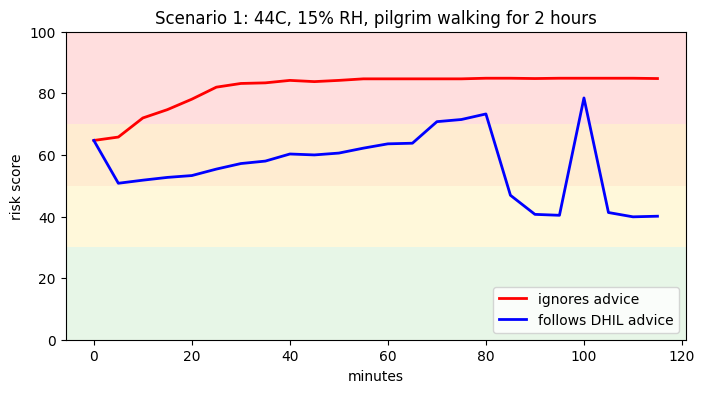

ignores advice  peak risk 85 | minutes in Critical 110
follows advice  peak risk 78 | minutes in Critical 20


In [ ]:
# Scenario 1: extreme heat, with and without DHIL advice
rec_ignore = run(new_system(44, 15, follow=False), name="scenario1_ignores_advice")
rec_follow = run(new_system(44, 15, follow=True), name="scenario1_follows_advice")

fig, ax = plt.subplots(figsize=(8, 4))
risk_axes(ax)
ax.plot([r["min"] for r in rec_ignore], [r["score"] for r in rec_ignore], "r-", lw=2, label="ignores advice")
ax.plot([r["min"] for r in rec_follow], [r["score"] for r in rec_follow], "b-", lw=2, label="follows DHIL advice")
ax.set_title("Scenario 1: 44C, 15% RH, pilgrim walking for 2 hours")
ax.legend(loc="lower right")
plt.show()

for name, rec in (("ignores advice", rec_ignore), ("follows advice", rec_follow)):
    crit = sum(r["cls"] == "Critical" for r in rec) * STEP_MIN
    print(f"{name:15} peak risk {max(r['score'] for r in rec):.0f} | minutes in Critical {crit}")

### Scenario 2: Health Agent failure

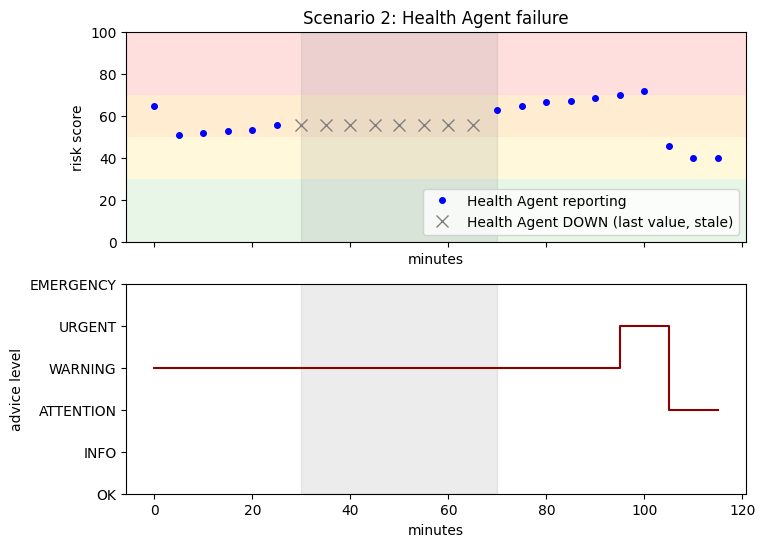

minute   0: WARNING   HIGH             -> rest_A
minute  35: WARNING   DEGRADED_DANGER  -> rest_A
minute  70: WARNING   HIGH             -> rest_C
minute  95: URGENT    CRITICAL         -> cool_C
minute 105: ATTENTION WATER            -> osm_8783559583

Undelivered messages (Health Agent down):
   #270 step=8 (REQUEST :sender prevention :receiver health :ontology dhil-heat-stress :conv risk-poll :content {'event': 'risk_report'})  [UNDELIVERED]
   #282 step=9 (INFORM :sender prevention :receiver health :ontology dhil-heat-stress :conv user-action :content {'event': 'rest_completed'})  [UNDELIVERED]
   #293 step=10 (REQUEST :sender prevention :receiver health :ontology dhil-heat-stress :conv risk-poll :content {'event': 'risk_report'})  [UNDELIVERED]


In [ ]:
# Scenario 2: the Health Agent goes down at minute 30 and comes back at minute 70
s = new_system(44, 15, follow=True)
rec = run(s, 24, {6: lambda s: s.bus.fail("health"), 14: lambda s: s.bus.recover("health")},
           name="scenario2_health_agent_failure")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
risk_axes(ax1)
live = [(r["min"], r["score"]) for r in rec if not r["stale"]]
down = [(r["min"], r["score"]) for r in rec if r["stale"]]
ax1.plot(*zip(*live), "b.", ms=8, label="Health Agent reporting")
ax1.plot(*zip(*down), "x", color="gray", ms=8, label="Health Agent DOWN (last value, stale)")
ax1.axvspan(30, 70, color="gray", alpha=0.15)
ax1.set_title("Scenario 2: Health Agent failure")
ax1.legend(loc="lower right")
ax2.step([r["min"] for r in rec], [LEVEL_NUM[r["level"]] for r in rec], where="post", color="darkred")
ax2.set_yticks(list(LEVEL_NUM.values()))
ax2.set_yticklabels(list(LEVEL_NUM.keys()))
ax2.axvspan(30, 70, color="gray", alpha=0.15)
ax2.set_xlabel("minutes")
ax2.set_ylabel("advice level")
plt.show()

prev = None
for r in rec:
    if r["code"] != prev:
        print(f"minute {r['min']:>3}: {r['level']:9} {r['code']:16} -> {r['station']}")
        prev = r["code"]
print("\nUndelivered messages (Health Agent down):")
for m in [m for m in s.bus.log if not m.delivered][:3]:
    print("  ", m)

### Scenario 3: station conflicts

In [ ]:
# Scenario 3: station conflicts
print("=== 3a: the nearest rest point is closed -> the Resource Agent negotiates with the others")
s = new_system(44, 15, follow=True)
def close_rest_a(s):
    for st in s.stations:
        if st.name == "rest_A":
            st.closed = True
rec = run(s, 3, {0: close_rest_a}, name="scenario3a_rest_point_closed")
negotiation(s)
print("advice:", rec[-1]["level"], rec[-1]["code"], "->", rec[-1]["station"])

print("\n=== 3b: every rest point is unavailable -> failure, escalation, medic call")
s = new_system(44, 15, follow=True)
def close_all_rest(s):
    for st in s.stations:
        if st.need == "rest":
            st.closed = True
rec = run(s, 3, {0: close_all_rest}, name="scenario3b_all_rest_points_closed")
negotiation(s)
for r in rec:
    print(f"minute {r['min']:>3}: {r['level']:9} {r['code']:9} station={r['station']} note={r['note']} medic={r['medic']}")

=== 3a: the nearest rest point is closed -> the Resource Agent negotiates with the others
   step  1 REQUEST  prevention -> resource  {'need': 'rest'}
   step  1 CFP      resource -> rest_A  {'need': 'rest'}
   step  1 CFP      resource -> rest_C  {'need': 'rest'}
   step  1 REFUSE   rest_A -> resource  {'reason': 'closed'}
   step  1 PROPOSE  rest_C -> resource  {'station': 'rest_C', 'need': 'rest', 'distance_m': 477, 'free': 15}
   step  1 ACCEPT   resource -> rest_C  {'need': 'rest'}
   step  1 INFORM   resource -> prevention  {'event': 'resource_assigned', 'need': 'rest', 'station': 'rest_C', 'distance_m': 477, 'eta_min': 8.0}
advice: WARNING HIGH -> rest_C

=== 3b: every rest point is unavailable -> failure, escalation, medic call
   step  1 REQUEST  prevention -> resource  {'need': 'rest'}
   step  1 CFP      resource -> rest_A  {'need': 'rest'}
   step  1 CFP      resource -> rest_C  {'need': 'rest'}
   step  1 REFUSE   rest_A -> resource  {'reason': 'closed'}
   step  1 REFUSE 

### Comparison table

In [ ]:
print(f"{'weather':12} {'pilgrim':16} {'peak risk':>10} {'minutes in Critical':>20}")
for temp, rh in ((44, 15), (40, 25), (36, 40)):
    for follow in (False, True):
        rec = run(new_system(temp, rh, follow))
        peak = max(r["score"] for r in rec)
        crit = sum(r["cls"] == "Critical" for r in rec) * STEP_MIN
        label = "follows advice" if follow else "ignores advice"
        print(f"{temp}C/{rh}%".ljust(12), label.ljust(16), f"{peak:10.0f} {crit:20d}")

weather      pilgrim           peak risk  minutes in Critical
44C/15%      ignores advice           85                  110
44C/15%      follows advice           78                   20
40C/25%      ignores advice           85                  100
40C/25%      follows advice           77                   10
36C/40%      ignores advice           84                   85
36C/40%      follows advice           67                    0


In [ ]:
# LangSmith evaluation: a dataset of test cases, a target that runs DHIL on each case, and a custom evaluator.
# Run this cell after the scenario helper cell (new_system, run) has been executed.
from langsmith import Client

client = Client()
DATASET_NAME = "DHIL-Scenario-Evaluation"

# Test cases: inputs are what the case runs, reference outputs are what we expect (written by the team).
cases = [
    ({"case": "44C, ignores advice", "kind": "weather", "temp": 44, "rh": 15, "follow": False}, {"critical_min_at_least": 60}),
    ({"case": "44C, follows advice", "kind": "weather", "temp": 44, "rh": 15, "follow": True}, {"critical_max_at_most": 30}),
    ({"case": "40C, ignores advice", "kind": "weather", "temp": 40, "rh": 25, "follow": False}, {"critical_min_at_least": 60}),
    ({"case": "40C, follows advice", "kind": "weather", "temp": 40, "rh": 25, "follow": True}, {"critical_max_at_most": 30}),
    ({"case": "36C, ignores advice", "kind": "weather", "temp": 36, "rh": 40, "follow": False}, {"critical_min_at_least": 60}),
    ({"case": "36C, follows advice", "kind": "weather", "temp": 36, "rh": 40, "follow": True}, {"critical_max_at_most": 30}),
    ({"case": "Health Agent failure", "kind": "health_failure"}, {"degraded_rule_expected": True}),
    ({"case": "nearest rest point closed", "kind": "rest_a_closed"}, {"station_expected": "rest_C"}),
    ({"case": "all rest points closed", "kind": "all_rest_closed"}, {"failure_expected": True, "medic_expected": True}),
]

existing = list(client.list_datasets(dataset_name=DATASET_NAME))
if existing:
    dataset = existing[0]
    print("Using existing dataset:", DATASET_NAME)
else:
    dataset = client.create_dataset(dataset_name=DATASET_NAME,
                                    description="Behaviour checks for the DHIL multi-agent heat-stress system.")
    client.create_examples(inputs=[c[0] for c in cases], outputs=[c[1] for c in cases], dataset_id=dataset.id)
    print("Dataset created with", len(cases), "test cases")
print("Dataset ID:", dataset.id)


def evaluation_target(inputs):
    """Run one DHIL case and return the observed outcome."""
    kind = inputs["kind"]
    if kind == "weather":
        rec = run(new_system(inputs["temp"], inputs["rh"], follow=inputs["follow"]), name="eval_" + inputs["case"])
        return {"critical_minutes": sum(r["cls"] == "Critical" for r in rec) * STEP_MIN,
                "peak_risk": max(r["score"] for r in rec)}
    if kind == "health_failure":
        s = new_system(44, 15, follow=True)
        rec = run(s, 24, {6: lambda s: s.bus.fail("health"), 14: lambda s: s.bus.recover("health")},
                  name="eval_health_failure")
        return {"degraded_rule_seen": any(r["code"].startswith("DEGRADED") for r in rec)}
    if kind == "rest_a_closed":
        s = new_system(44, 15, follow=True)

        def close_rest_a(s):
            for st in s.stations:
                if st.name == "rest_A":
                    st.closed = True
        rec = run(s, 3, {0: close_rest_a}, name="eval_rest_a_closed")
        return {"station": rec[-1]["station"]}
    s = new_system(44, 15, follow=True)

    def close_all_rest(s):
        for st in s.stations:
            if st.need == "rest":
                st.closed = True
    rec = run(s, 3, {0: close_all_rest}, name="eval_all_rest_closed")
    return {"failure_seen": any(m.performative == "FAILURE" for m in s.bus.log),
            "medic_called": any(r["medic"] for r in rec)}


def dhil_evaluator(run, example):
    """Score 1 when the observed outcome matches every expectation of the case."""
    actual, expected = run.outputs or {}, example.outputs or {}
    checks = []
    if "critical_min_at_least" in expected:
        checks.append(("critical minutes", actual.get("critical_minutes", -1) >= expected["critical_min_at_least"]))
    if "critical_max_at_most" in expected:
        checks.append(("critical minutes", actual.get("critical_minutes", 10**6) <= expected["critical_max_at_most"]))
    if "degraded_rule_expected" in expected:
        checks.append(("degraded rule", actual.get("degraded_rule_seen") == expected["degraded_rule_expected"]))
    if "station_expected" in expected:
        checks.append(("station", actual.get("station") == expected["station_expected"]))
    if "failure_expected" in expected:
        checks.append(("failure message", actual.get("failure_seen") == expected["failure_expected"]))
    if "medic_expected" in expected:
        checks.append(("medic call", actual.get("medic_called") == expected["medic_expected"]))
    failed = [name for name, ok in checks if not ok]
    return {"key": "behaviour_correct", "score": 0.0 if failed else 1.0,
            "comment": "Correct" if not failed else f"Failed: {', '.join(failed)}. Expected {expected}, got {actual}"}


evaluation_results = client.evaluate(
    evaluation_target,
    data=DATASET_NAME,
    evaluators=[dhil_evaluator],
    experiment_prefix="DHIL-Evaluation",
    description="Behaviour checks for the DHIL multi-agent heat-stress system (simulation).",
)

print("Evaluation completed!")

Dataset created with 9 test cases
Dataset ID: 88f9348d-7c7c-4161-b4e2-d821ad38665c
View the evaluation results for experiment: 'DHIL-Evaluation-9b54ef3e' at:
https://smith.langchain.com/o/b31f6575-1fe1-45a1-852c-cce5813ebe2c/datasets/88f9348d-7c7c-4161-b4e2-d821ad38665c/compare?selectedSessions=69067d13-8a64-4cee-8c6e-7662f6f148d8




0it [00:00, ?it/s]

Evaluation completed!


In [ ]:
# ACL communication log as a table (same columns as the lab): one row per message of a scenario.
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)


def acl_table(s, only_important=True):
    """Return the message log of a DHILSystem run as a DataFrame."""
    skip = {"risk_update", "heat_update"} if only_important else set()
    rows = []
    for m in s.bus.log:
        event = m.content.get("event")
        if event in skip:
            continue
        detail = {k: v for k, v in m.content.items()
                  if k in ("need", "station", "reason", "event", "eta_min", "distance_m", "free")}
        rows.append({
            "minute": m.step * STEP_MIN,
            "sender": m.sender,
            "receiver": m.receiver,
            "performative": m.performative,
            "content": str(detail) if detail else str(m.content)[:80],
            "delivered": "yes" if m.delivered else "NO",
        })
    return pd.DataFrame(rows)


# Example: scenario 3a (the nearest rest point is closed) and 3b (every rest point is closed)
def close_rest_a(s):
    for st in s.stations:
        if st.name == "rest_A":
            st.closed = True


def close_all_rest(s):
    for st in s.stations:
        if st.need == "rest":
            st.closed = True


s3a = new_system(44, 15, follow=True)
run(s3a, 3, {0: close_rest_a}, name="acl_table_3a")
print("ACL COMMUNICATION LOG - scenario 3a (rest_A closed)")
print("=" * 55)
display(acl_table(s3a))

s3b = new_system(44, 15, follow=True)
run(s3b, 3, {0: close_all_rest}, name="acl_table_3b")
print("\nACL COMMUNICATION LOG - scenario 3b (all rest points closed)")
print("=" * 55)
display(acl_table(s3b))
print("\nNumber of messages in 3b:", len(s3b.bus.log))

ACL COMMUNICATION LOG - scenario 3a (rest_A closed)


,minute,sender,receiver,performative,content,delivered
0,5,prevention,resource,REQUEST,{'need': 'rest'},yes
1,5,resource,rest_A,CFP,{'need': 'rest'},yes
2,5,resource,rest_C,CFP,{'need': 'rest'},yes
3,5,rest_A,resource,REFUSE,{'reason': 'closed'},yes
4,5,rest_C,resource,PROPOSE,"{'station': 'rest_C', 'need': 'rest', 'distance_m': 477, 'free': 15}",yes
5,5,resource,rest_C,ACCEPT,{'need': 'rest'},yes
6,5,rest_C,resource,INFORM,"{'event': 'reserved', 'station': 'rest_C'}",yes
7,5,resource,prevention,INFORM,"{'event': 'resource_assigned', 'need': 'rest', 'station': 'rest_C', 'distance_m': 477,...",yes
8,5,prevention,route,REQUEST,"{'origin': (-199.1027334401769, -300.4627302000528), 'dest': (51.93894238312002,",yes
9,5,route,prevention,INFORM,"{'event': 'route_ready', 'distance_m': 526, 'eta_min': 6.6}",yes



ACL COMMUNICATION LOG - scenario 3b (all rest points closed)


,minute,sender,receiver,performative,content,delivered
0,5,prevention,resource,REQUEST,{'need': 'rest'},yes
1,5,resource,rest_A,CFP,{'need': 'rest'},yes
2,5,resource,rest_C,CFP,{'need': 'rest'},yes
3,5,rest_A,resource,REFUSE,{'reason': 'closed'},yes
4,5,rest_C,resource,REFUSE,{'reason': 'closed'},yes
5,5,resource,prevention,FAILURE,"{'event': 'resource_unavailable', 'need': 'rest', 'reason': 'all_stations_unavailable'}",yes
6,10,prevention,health,REQUEST,{'event': 'risk_report'},yes
7,15,prevention,resource,REQUEST,{'need': 'cooling'},yes
8,15,resource,cool_A,CFP,{'need': 'cooling'},yes
9,15,resource,cool_B,CFP,{'need': 'cooling'},yes



Number of messages in 3b: 26


## 7. Save your work

In [ ]:
# Download the files you need to keep (Colab deletes files when the session ends)
try:
    from google.colab import files
    for f in ("health_model.joblib", "haram_map.html"):
        if os.path.exists(f):
            files.download(f)
except ImportError:
    print("not running in Colab")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>